# Exploring the embeddings for Raman Spectra

# Import & Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from tensorflow.keras import layers
# import tensorflow_addons as tfa
from tensorflow import keras
import tensorflow as tf
from datetime import datetime
import matplotlib.pyplot as plt
import numpy as np
import json
import random
import scipy.io as sio


from keras.utils import CustomObjectScope
from keras.initializers import glorot_uniform

# Setting seeds for reproducibility.
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

In [ ]:
# DATA
BUFFER_SIZE = 1024
BATCH_SIZE = 256
AUTO = tf.data.AUTOTUNE
INPUT_SHAPE = (20, 20, 1)
NUM_CLASSES = 10

# OPTIMIZER
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 1e-5

# TRAINING
EPOCHS = 100

# AUGMENTATION
IMAGE_SIZE = 20  # We'll resize input images to this size.
PATCH_SIZE = 5  # Size of the patches to be extract from the input images.
NUM_PATCHES = (IMAGE_SIZE // PATCH_SIZE) ** 2
MASK_PROPORTION = 0.5

# ENCODER and DECODER
LAYER_NORM_EPS = 1e-6
ENC_PROJECTION_DIM = 64
DEC_PROJECTION_DIM = 32
ENC_NUM_HEADS = 4
ENC_LAYERS = 3
DEC_NUM_HEADS = 4
DEC_LAYERS = 1 # The decoder is lightweight but should be reasonably deep for reconstruction.
ENC_TRANSFORMER_UNITS = [
    ENC_PROJECTION_DIM * 2,
    ENC_PROJECTION_DIM,
]  # Size of the transformer layers.
DEC_TRANSFORMER_UNITS = [
    DEC_PROJECTION_DIM * 2,
    DEC_PROJECTION_DIM,
]

# Dataset

Read data from the Google Drive here

In [ ]:
data_train_outputs = sio.loadmat('drive/MyDrive/Raman_ViT_data/Train_Outputs.mat')
data_train_outputs = data_train_outputs['Train_Outputs']
data_test_outputs = sio.loadmat('drive/MyDrive/Raman_ViT_data/Test_Outputs.mat')
data_test_outputs = data_test_outputs['Test_Outputs']
data_val_outputs = data_test_outputs[:int(data_test_outputs.shape[0]/2),:]
data_test_outputs = data_test_outputs[int(data_test_outputs.shape[0]/2):,:]
print(f"Training samples: {data_train_outputs.shape}")
print(f"Validation samples: {data_val_outputs.shape}")
print(f"Testing samples: {data_test_outputs.shape}")



Training samples: (159618, 500)
Validation samples: (6347, 500)
Testing samples: (6347, 500)


In [ ]:
# data_cell = sio.loadmat('drive/MyDrive/Raman_ViT_data/Cell_01_Out_532_BG.mat')
# dataim = data_cell['Large_Area_Scan_004_SpecData_1_BR_BR_Sub_BG']
# im_var = dataim[0][0][7][:,:500]

In [ ]:
## Shape and batch fetch the training, validation, and test data batches

@tf.numpy_function(Tout=tf.float64)
def prep_image(vec, patch_size):
  img_size = int(np.sqrt(vec.shape[0]))

  img = -1*np.ones([img_size, img_size, 1])

  for i in range(0, img_size, patch_size):

    for j in range(0, img_size, patch_size):

      img[i:i+patch_size, j:j+patch_size, :] = np.reshape(vec[((i*(img_size//patch_size)*patch_size) + (j*patch_size)): ((i*(img_size//patch_size)*patch_size) + (j*patch_size) + (patch_size*patch_size))], [patch_size, patch_size, 1])

  return img


def prep_image_tf(vec, patch_size):
    """
    Recreates the image from the vector using TensorFlow operations.
    This function is designed to be compatible with TensorFlow's automatic differentiation,
    unlike the tf.numpy_function based approach.

    Args:
    vec: The input vector representing the image data.
    patch_size: The size of the patches to be extracted.

    Returns:
    img: The reconstructed image as a TensorFlow tensor.
    """
    img_size = int(np.sqrt(vec.shape[0]))
    img = -1 * tf.ones([img_size, img_size, 1], dtype=tf.float64)

    # Calculate patch indices
    indices = []
    for i in range(0, img_size, patch_size):
        for j in range(0, img_size, patch_size):
            start = (i * (img_size // patch_size) * patch_size) + (j * patch_size)
            end = start + (patch_size * patch_size)
            indices.extend(list(range(start, end)))

    indices = tf.constant(indices, dtype=tf.int32)

    # Reshape and assign patches to image
    patches = tf.gather(vec, indices)
    patches = tf.reshape(patches, [img_size // patch_size, img_size // patch_size, patch_size, patch_size, 1])

    # Concatenate the image in two steps: horizontally and then vertically.
    rows = [tf.concat(tf.unstack(x), axis=1) for x in tf.unstack(patches)]
    img = tf.concat(rows, axis=0)

    return img




train_ds = tf.data.Dataset.from_tensor_slices((data_train_outputs[:, :400]))
train_ds = train_ds.map(lambda x: tf.reshape(prep_image_tf(x, PATCH_SIZE), [20, 20, 1]))
train_ds = train_ds.shuffle(BUFFER_SIZE).batch(BATCH_SIZE).prefetch(AUTO) #.map(lambda x: prep_image2(x, PATCH_SIZE))


val_ds = tf.data.Dataset.from_tensor_slices((data_val_outputs[:, :400]))
val_ds = val_ds.map(lambda x: tf.reshape(prep_image_tf(x, PATCH_SIZE), [20, 20, 1]))
val_ds = val_ds.shuffle(BUFFER_SIZE).batch(BATCH_SIZE).prefetch(AUTO)

test_ds = tf.data.Dataset.from_tensor_slices((data_test_outputs[:, :400]))
test_ds = test_ds.map(lambda x: tf.reshape(prep_image_tf(x, PATCH_SIZE), [20, 20, 1]))
test_ds = test_ds.shuffle(BUFFER_SIZE).batch(BATCH_SIZE).prefetch(AUTO)

# im_ds = tf.data.Dataset.from_tensor_slices((im_var[:, :400]))
# im_ds = im_ds.map(lambda x: tf.reshape(prep_image_tf(x, PATCH_SIZE), [20, 20, 1]))
# im_ds = im_ds.batch(BATCH_SIZE).prefetch(AUTO)

In [ ]:
## Load the secondary dataset for classificaiton
data_organo = sio.loadmat('/content/drive/MyDrive/Raman_ViT_data/variables_231CTCLM_updated_pcrem_200421_rev.mat')
All_wn = data_organo['wn']
All_wn_red = All_wn[:,:800][:,::2]

All_spectra = data_organo['All_filt']
All_class = data_organo['labels_table_class']
All_cell = data_organo['labels_table_cell']
All_conc = data_organo['labels_table_conc']
All_cell_bg = data_organo['labels_table_status_cell1_bg0']

##Removing nan rows
nan_rows = np.isnan(All_spectra).any(axis=1)
All_spectra = All_spectra[~nan_rows]
All_class = All_class[~nan_rows]
All_cell = All_cell[~nan_rows]
All_conc = All_conc[~nan_rows]
All_cell_bg = All_cell_bg[~nan_rows]


from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize  # For normr equivalent
pca = PCA()
score_pca = pca.fit_transform(All_spectra)  # Equivalent to score_pca in MATLAB
coeff_pca = pca.components_  # Equivalent to coeff_pca in MATLAB
latent = pca.explained_variance_  # Equivalent to latent in MATLAB

# Modifying score_pca (setting columns 4 and 5 to zero)
score_pca_new = score_pca.copy()
score_pca_new[:, [3, 4]] = 0  # Python uses 0-based indexing
# Reconstructing and normalizing
All_cons = score_pca_new @ coeff_pca + All_spectra - (score_pca @ coeff_pca)
All_spectra = normalize(All_cons, axis=1)


All_spectra_red = All_spectra[:, :800][:,::2]

All_spectra_red_shuff = All_spectra_red.copy()
All_spectra_red_shuff = All_spectra_red_shuff[All_cell_bg[:,0] == 1,:]
np.random.shuffle(All_spectra_red_shuff)
train_all = All_spectra_red_shuff[:int(All_spectra_red_shuff.shape[0]/5),:]
val_all = All_spectra_red_shuff[int(All_spectra_red_shuff.shape[0]/5):,:]

# All_spec_ds = tf.data.Dataset.from_tensor_slices((All_spectra_red))
# All_spec_ds = All_spec_ds.map(lambda x: tf.reshape(prep_image(x, PATCH_SIZE), [20, 20, 1]))
# All_spec_ds = All_spec_ds.batch(BATCH_SIZE).prefetch(AUTO)

All_spec_filt = All_spectra_red[(All_cell_bg[:, 0] == 1)& (All_conc[:, 0] == 1), :]
All_spec_filt_ds = tf.data.Dataset.from_tensor_slices((All_spec_filt)).batch(BATCH_SIZE).prefetch(AUTO)
All_class_filt = All_class[(All_cell_bg[:, 0] == 1)& (All_conc[:, 0] == 1), :]
All_cell_filt = All_cell[(All_cell_bg[:, 0] == 1)& (All_conc[:, 0] == 1), :]




train_all_ds = tf.data.Dataset.from_tensor_slices(train_all)
train_all_ds = train_all_ds.map(lambda x: tf.reshape(prep_image_tf(x, PATCH_SIZE), [20, 20, 1]))
train_all_ds = train_all_ds.shuffle(BUFFER_SIZE).batch(BATCH_SIZE).prefetch(AUTO) #.map(lambda x: prep_image2(x, PATCH_SIZE))


val_all_ds = tf.data.Dataset.from_tensor_slices(val_all)
val_all_ds = val_all_ds.map(lambda x: tf.reshape(prep_image_tf(x, PATCH_SIZE), [20, 20, 1]))
val_all_ds = val_all_ds.shuffle(BUFFER_SIZE).batch(BATCH_SIZE).prefetch(AUTO)

## Variables to use for classification
print(All_spec_filt_ds)
print(All_class_filt.shape)
print(All_cell_filt.shape)

print(np.unique(All_cell_filt))


/usr/local/lib/python3.11/dist-packages/scipy/io/matlab/_mio.py:227: MatReadWarning: Duplicate variable name "None" in stream - replacing previous with new
Consider mio5.varmats_from_mat to split file into single variable files
  matfile_dict = MR.get_variables(variable_names)


<_PrefetchDataset element_spec=TensorSpec(shape=(None, 400), dtype=tf.float64, name=None)>
(1927, 1)
(1927, 1)
[  1   2   3   4   5   6   7   8   9  10  70  71  72  73  74  75  76 137
 138 139 140 141 142 143 144 145 146]


In [ ]:
# data_rf = sio.loadmat('/content/drive/MyDrive/Raman_ViT_data/rf_results_0uM_231CTCLM_200620.mat')
# data_rf['All_filt'].shape

In [ ]:
# len(np.unique(All_cell_filt))

In [ ]:
## Final updated data for classification

data_rf = sio.loadmat('/content/drive/MyDrive/Raman_ViT_data/rf_results_0uM_231CTCLM_200620.mat')
All_spec_filt = data_rf['Reduced_data'][:,:800][:,::2]
## Variables to use for classification
All_spec_filt_ds = tf.data.Dataset.from_tensor_slices((All_spec_filt)).batch(BATCH_SIZE).prefetch(AUTO)
All_class_filt = data_rf['Reduced_class']
All_cell_filt = data_rf['Reduced_cell']
print(All_cell_filt.shape)

# All_spec_filt_ds - final dataset to train on

(3034, 1)


In [ ]:
# spectra = data_rf['spectra']
# plt.plot(wn[0,:], spectra[100, :])

# Data Augmentation

In [ ]:
def get_train_augmentation_model():
    model = keras.Sequential( [layers.Rescaling(1)], name="train_data_augmentation")
    return model


def get_test_augmentation_model():
    model = keras.Sequential( [layers.Rescaling(1)], name="test_data_augmentation")
    return model

# Create Patches

This layer creates patches from input images. The layer also consists of two utility methods:
- `show_patched_image`: This utility function takes a batch of images and its corresponding patches, randomly choses a pair and plots it. This is useful for a sanity check.
- `reconstruct_from_patch`: This utility funciton takes the patches of a **single** image, and reconstructs it back into the original image. This is useful for the training monitor callback defined later.

In [ ]:
class Patches(layers.Layer):
    def __init__(self, patch_size=PATCH_SIZE, **kwargs):
        super().__init__(**kwargs)
        self.patch_size = patch_size

        # Assuming the image has three channels each patch would be
        # of size (patch_size, patch_size, 3).
        self.resize = layers.Reshape((-1, patch_size * patch_size * 1))

    def call(self, images):
        # Create patches from the input images
        patches = tf.image.extract_patches(
            images=images,
            sizes=[1, self.patch_size, self.patch_size, 1],
            strides=[1, self.patch_size, self.patch_size, 1],
            rates=[1, 1, 1, 1],
            padding="VALID",
        )

        # Reshape the patches to (batch, num_patches, patch_area) and return it.
        patches = self.resize(patches)
        return patches

    def show_patched_image(self, images, patches):
        # This is a utility function which accepts a batch of images and its
        # corresponding patches and help visualize one image and its patches
        # side by side.
        idx = np.random.choice(patches.shape[0])
        print(f"Index selected: {idx}.")

        plt.figure(figsize=(4, 4))
        plt.imshow(keras.utils.array_to_img(images[idx]))
        plt.axis("off")
        plt.show()

        n = int(np.sqrt(patches.shape[1]))
        plt.figure(figsize=(4, 4))
        for i, patch in enumerate(patches[idx]):
            ax = plt.subplot(n, n, i + 1)
            patch_img = tf.reshape(patch, (self.patch_size, self.patch_size, 1))
            plt.imshow(keras.utils.img_to_array(patch_img))
            plt.axis("off")
        plt.show()

        # Return the index chosen to validate it outside the method.
        return idx

    # taken from https://stackoverflow.com/a/58082878/10319735
    def reconstruct_from_patch(self, patch):
        # This utility function takes patches from a *single* image and
        # reconstructs it back into the image. This is useful for the train
        # monitor callback.
        num_patches = patch.shape[0]
        n = int(np.sqrt(num_patches))
        patch = tf.reshape(patch, (num_patches, self.patch_size, self.patch_size, 1))
        rows = tf.split(patch, n, axis=0)
        rows = [tf.concat(tf.unstack(x), axis=1) for x in rows]
        reconstructed = tf.concat(rows, axis=0)
        return reconstructed


    def reconstruct_spectrum_from_patch(self, patch):
        num_patches = patch.shape[0]
        recon_spectrum = tf.reshape(patch, [num_patches, -1])
        recon_spectrum = tf.reshape(recon_spectrum, [1, -1])
        return recon_spectrum

    def reconstruct_spectrum_from_image(self, images):
        patch_loc = self.call(images)
        recon_spectrum_im = self.reconstruct_spectrum_from_patch(patch_loc)
        return recon_spectrum_im

    #     return recon_spectrum

# Patch Encoder

This layer deals with encoding the pathces and adding the positional embedding too. The layer holds two utility functions:
- `get_random_indices`: This function provides randomly sampled mask and unmask indices.
- `show_masked_image`: A utility function that plots a random masked image.

In [ ]:
class PatchEncoder(layers.Layer):
    def __init__(
        self,
        patch_size=PATCH_SIZE,
        projection_dim=ENC_PROJECTION_DIM,
        mask_proportion=MASK_PROPORTION,
        downstream=False,
        # START_PATCH_NUM=START_PATCH_NUM,
        **kwargs,
    ):
        super().__init__(**kwargs)
        self.patch_size = patch_size
        self.projection_dim = projection_dim
        self.mask_proportion = mask_proportion
        self.downstream = downstream
        # self.START_PATCH_NUM = START_PATCH_NUM

        # This is a trainable mask token initialized randomly from a normal
        # distribution.
        self.mask_token = tf.Variable(
            tf.random.normal([1, patch_size * patch_size * 1]), trainable=True
        )

    def build(self, input_shape):
        (_, self.num_patches, self.patch_area) = input_shape

        # Create the projection layer for the patches.
        self.projection = layers.Dense(units=self.projection_dim)

        # Create the positional embedding layer.
        self.position_embedding = layers.Embedding(
            input_dim=self.num_patches, output_dim=self.projection_dim
        )

        # Number of patches that will be masked.
        self.num_mask = int(self.mask_proportion * self.num_patches)

    def call(self, patches):
        # Get the positional embeddings.
        batch_size = tf.shape(patches)[0]
        # Here, instead of 0 to n-1, can we add normalized values of the x-axis from data_wn
        positions = tf.range(start=0, limit=self.num_patches, delta=1)
        pos_embeddings = self.position_embedding(positions[tf.newaxis, ...])
        pos_embeddings = tf.tile(
            pos_embeddings, [batch_size, 1, 1]
        )  # (B, num_patches, projection_dim)
        # print(pos_embeddings.shape)
        # Embed the patches.
        patch_embeddings = (
            self.projection(patches) + pos_embeddings
        )  # (B, num_patches, projection_dim)
        # print(patch_embeddings.shape)

        if self.downstream:
            return patch_embeddings
        else:
            mask_indices, unmask_indices = self.get_random_indices(batch_size)
            # The encoder input is the unmasked patch embeddings. Here we gather
            # all the patches that should be unmasked.
            unmasked_embeddings = tf.gather(
                patch_embeddings, unmask_indices, axis=1, batch_dims=1
            )  # (B, unmask_numbers, projection_dim)

            # Get the unmasked and masked position embeddings. We will need them
            # for the decoder.
            unmasked_positions = tf.gather(
                pos_embeddings, unmask_indices, axis=1, batch_dims=1
            )  # (B, unmask_numbers, projection_dim)
            masked_positions = tf.gather(
                pos_embeddings, mask_indices, axis=1, batch_dims=1
            )  # (B, mask_numbers, projection_dim)

            # Repeat the mask token number of mask times.
            # Mask tokens replace the masks of the image.
            mask_tokens = tf.repeat(self.mask_token, repeats=self.num_mask, axis=0)
            mask_tokens = tf.repeat(
                mask_tokens[tf.newaxis, ...], repeats=batch_size, axis=0
            )

            # Get the masked embeddings for the tokens.
            masked_embeddings = self.projection(mask_tokens) + masked_positions
            return (
                unmasked_embeddings,  # input to the encoder
                masked_embeddings,  # first part of input to the decoder
                unmasked_positions,  # added to the encoder outputs
                mask_indices,  # the indices that were masked
                unmask_indices,  # the indices that were unmaksed
            )

    def get_random_indices(self, batch_size):
        # Create random indices from a uniform distribution and then split
        # it into mask and unmask indices.
        rand_indices = tf.argsort(
            tf.random.uniform(shape=(batch_size, self.num_patches)), axis=-1
        )
        mask_indices = rand_indices[:, : self.num_mask]
        unmask_indices = rand_indices[:, self.num_mask :]

        return mask_indices, unmask_indices

    def show_masked_image(self, patches, unmask_indices):
        # choose a random patch and it corresponding unmask index
        idx = np.random.choice(patches.shape[0])
        patch = patches[idx]
        unmask_index = unmask_indices[idx]

        # build a numpy array of same shape as pathc
        new_patch = np.zeros_like(patch)

        # iterate of the new_patch and plug the unmasked patches
        count = 0
        for i in range(unmask_index.shape[0]):
            new_patch[unmask_index[i]] = patch[unmask_index[i]]
        return new_patch, idx

# MLP

In [ ]:
def mlp(x, dropout_rate, hidden_units):
    for units in hidden_units:
        x = layers.Dense(units, activation=tf.nn.gelu)(x)
        x = layers.Dropout(dropout_rate)(x)
    return x

# Encoder

In [ ]:
def create_encoder(num_heads=ENC_NUM_HEADS, num_layers=ENC_LAYERS):
    inputs = layers.Input((None, ENC_PROJECTION_DIM))
    x = inputs

    for _ in range(num_layers):
        # Layer normalization 1.
        x1 = layers.LayerNormalization(epsilon=LAYER_NORM_EPS)(x)

        # Create a multi-head attention layer.
        attention_output = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=ENC_PROJECTION_DIM, dropout=0.1
        )(x1, x1)

        # Skip connection 1.
        x2 = layers.Add()([attention_output, x])

        # Layer normalization 2.
        x3 = layers.LayerNormalization(epsilon=LAYER_NORM_EPS)(x2)

        # MLP.
        x3 = mlp(x3, hidden_units=ENC_TRANSFORMER_UNITS, dropout_rate=0.1)

        # Skip connection 2.
        x = layers.Add()([x3, x2])

    outputs = layers.LayerNormalization(epsilon=LAYER_NORM_EPS)(x)
    return keras.Model(inputs, outputs, name="mae_encoder")

# Decoder

In [ ]:
def create_decoder(
    num_layers=DEC_LAYERS, num_heads=DEC_NUM_HEADS, image_size=IMAGE_SIZE
):
    inputs = layers.Input((NUM_PATCHES, ENC_PROJECTION_DIM))
    x = layers.Dense(DEC_PROJECTION_DIM)(inputs)

    for _ in range(num_layers):
        # Layer normalization 1.
        x1 = layers.LayerNormalization(epsilon=LAYER_NORM_EPS)(x)

        # Create a multi-head attention layer.
        attention_output = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=DEC_PROJECTION_DIM, dropout=0.1
        )(x1, x1)

        # Skip connection 1.
        x2 = layers.Add()([attention_output, x])

        # Layer normalization 2.
        x3 = layers.LayerNormalization(epsilon=LAYER_NORM_EPS)(x2)

        # MLP.
        x3 = mlp(x3, hidden_units=DEC_TRANSFORMER_UNITS, dropout_rate=0.1)

        # Skip connection 2.
        x = layers.Add()([x3, x2])

    x = layers.LayerNormalization(epsilon=LAYER_NORM_EPS)(x)
    x = layers.Flatten()(x)
    pre_final = layers.Dense(units=image_size * image_size * 1, activation="sigmoid")(x)
    outputs = layers.Reshape((image_size, image_size, 1))(pre_final)

    return keras.Model(inputs, outputs, name="mae_decoder")

# MaskedAutoEncoder Model

This is the trainer model where we encapsulate the training logic.

In [ ]:
# @keras.saving.register_keras_serializable()
class MaskedAutoencoder(keras.Model):
    def __init__(
        self,
        train_augmentation_model,
        test_augmentation_model,
        patch_layer,
        patch_encoder,
        encoder,
        decoder,
        **kwargs
    ):
        super().__init__(**kwargs)
        self.train_augmentation_model = train_augmentation_model
        self.test_augmentation_model = test_augmentation_model
        self.patch_layer = patch_layer
        self.patch_encoder = patch_encoder
        self.encoder = encoder
        self.decoder = decoder

    def calculate_loss(self, images, test=False):
        # Augment the input images.
        if test:
            augmeneted_images = self.test_augmentation_model(images)
        else:
            augmeneted_images = self.train_augmentation_model(images)

        # Patch the augmented images.
        patches = self.patch_layer(augmeneted_images)

        # Encode the patches.
        (
            unmasked_embeddings,
            masked_embeddings,
            unmasked_positions,
            mask_indices,
            unmask_indices,
        ) = self.patch_encoder(patches)

        # Pass the unmaksed patche to the encoder.
        encoder_outputs = self.encoder(unmasked_embeddings)

        # Create the decoder inputs.
        encoder_outputs = encoder_outputs + unmasked_positions
        decoder_inputs = tf.concat([encoder_outputs, masked_embeddings], axis=1)

        # Decode the inputs.
        decoder_outputs = self.decoder(decoder_inputs)
        decoder_patches = self.patch_layer(decoder_outputs)

        loss_patch = tf.gather(patches, mask_indices, axis=1, batch_dims=1)
        loss_output = tf.gather(decoder_patches, mask_indices, axis=1, batch_dims=1)

        # Compute the total loss.
        total_loss = self.compiled_loss(loss_patch, loss_output)

        return total_loss, loss_patch, loss_output

    def train_step(self, images):
        with tf.GradientTape() as tape:
            total_loss, loss_patch, loss_output = self.calculate_loss(images)

        # Apply gradients.
        train_vars = [
            self.train_augmentation_model.trainable_variables,
            self.patch_layer.trainable_variables,
            self.patch_encoder.trainable_variables,
            self.encoder.trainable_variables,
            self.decoder.trainable_variables,
        ]
        grads = tape.gradient(total_loss, train_vars)
        tv_list = []
        for (grad, var) in zip(grads, train_vars):
            for g, v in zip(grad, var):
                tv_list.append((g, v))
        self.optimizer.apply_gradients(tv_list)

        # Report progress.
        self.compiled_metrics.update_state(loss_patch, loss_output)
        return {m.name: m.result() for m in self.metrics}

    def test_step(self, images):
        total_loss, loss_patch, loss_output = self.calculate_loss(images, test=True)

        # Update the trackers.
        self.compiled_metrics.update_state(loss_patch, loss_output)
        return {m.name: m.result() for m in self.metrics}


    def call(self, images, training=False):
        # Augment the input images.
        if training:
            augmeneted_images = self.train_augmentation_model(images)
        else:
            augmeneted_images = self.test_augmentation_model(images)

        # Patch the augmented images.
        patches = self.patch_layer(augmeneted_images)

        # Encode the patches.
        (
            unmasked_embeddings,
            masked_embeddings,
            unmasked_positions,
            mask_indices,
            unmask_indices,
        ) = self.patch_encoder(patches)

        # Pass the unmaksed patche to the encoder.
        encoder_outputs = self.encoder(unmasked_embeddings)

        # Create the decoder inputs.
        encoder_outputs = encoder_outputs + unmasked_positions
        decoder_inputs = tf.concat([encoder_outputs, masked_embeddings], axis=1)

        # Decode the inputs.
        decoder_outputs = self.decoder(decoder_inputs)

        return decoder_outputs, augmeneted_images  # Return the reconstructed images

    def get_config(self):
        config = super().get_config()
        config.update(
            {
                "train_augmentation_model": self.train_augmentation_model.get_config(), # Get config of Sequential model
                "test_augmentation_model": self.test_augmentation_model.get_config(), # Get config of Sequential model
                "patch_layer": self.patch_layer.get_config(),
                "patch_encoder": self.patch_encoder.get_config(),
                "encoder": self.encoder.get_config(),
                "decoder": self.decoder.get_config(),
            }
        )
        return config

    @classmethod
    def from_config(cls, config):
        train_augmentation_model = keras.Sequential.from_config(config.pop('train_augmentation_model')) # Reconstruct from config
        test_augmentation_model = keras.Sequential.from_config(config.pop('test_augmentation_model')) # Reconstruct from config
        patch_layer = Patches.from_config(config.pop('patch_layer'))
        patch_encoder = PatchEncoder.from_config(config.pop('patch_encoder'))
        encoder = keras.Model.from_config(config.pop('encoder'))
        decoder = keras.Model.from_config(config.pop('decoder'))

        return cls(train_augmentation_model=train_augmentation_model,
                   test_augmentation_model=test_augmentation_model,
                   patch_layer=patch_layer,
                   patch_encoder=patch_encoder,
                   encoder=encoder,
                   decoder=decoder,
                   **config)

In [ ]:
# Taking a batch of test inputs to measure model's progress.
test_images = next(iter(val_all_ds))

class TrainMonitor(tf.keras.callbacks.Callback):
    def __init__(self, epoch_interval=None):
        self.epoch_interval = epoch_interval

    def on_epoch_end(self, epoch, logs=None):
        if self.epoch_interval and epoch % self.epoch_interval == 0:
            test_augmeneted_images = self.model.test_augmentation_model(test_images)
            test_patches = self.model.patch_layer(test_augmeneted_images)
            (
                test_unmasked_embeddings,
                test_masked_embeddings,
                test_unmasked_positions,
                test_mask_indices,
                test_unmask_indices,
            ) = self.model.patch_encoder(test_patches)
            test_encoder_outputs = self.model.encoder(test_unmasked_embeddings)
            test_encoder_outputs = test_encoder_outputs + test_unmasked_positions
            test_decoder_inputs = tf.concat(
                [test_encoder_outputs, test_masked_embeddings], axis=1
            )
            test_decoder_outputs = self.model.decoder(test_decoder_inputs)

            # Show a maksed patch image.
            test_masked_patch, idx = self.model.patch_encoder.show_masked_image(
                test_patches, test_unmask_indices
            )
            print(f"\nIdx chosen: {idx}")
            original_image = test_augmeneted_images[idx]
            original_image_temp = tf.expand_dims(original_image, axis=0)
            original_spectrum = self.model.patch_layer.reconstruct_spectrum_from_image(original_image_temp)

            masked_image = self.model.patch_layer.reconstruct_from_patch(
                test_masked_patch
            )
            reconstructed_image = test_decoder_outputs[idx]
            reconstructed_image_temp = tf.expand_dims(reconstructed_image, axis=0)

            # recon_patches = self.model.patch_layer(reconstructed_image)
            recon_spectrum = self.model.patch_layer.reconstruct_spectrum_from_image(reconstructed_image_temp)

            fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(15, 5))
            ax[0,0].imshow(original_image)
            ax[0,0].set_title(f"Original: {epoch:03d}")

            ax[0,1].imshow(masked_image)
            ax[0,1].set_title(f"Masked: {epoch:03d}")

            ax[0,2].imshow(reconstructed_image)
            ax[0,2].set_title(f"Resonstructed: {epoch:03d}")

            ax[1,0].plot(range(len(original_spectrum[0])), np.transpose(original_spectrum))
            ax[1,0].set_title(f"Original: {epoch:03d}")

            ax[1,1].plot(range(len(recon_spectrum[0])), np.transpose(recon_spectrum))
            ax[1,1].set_title(f"Reconstructed: {epoch:03d}")

            ax[1,2].plot(range(len(recon_spectrum[0])), np.transpose(recon_spectrum))
            ax[1,2].plot(range(len(recon_spectrum[0])), np.transpose(original_spectrum))
            ax[1,2].set_title(f"Overlap: {epoch:03d}")



            plt.show()
            plt.close()



timestamp = datetime.utcnow().strftime("%y%m%d-%H%M%S")

train_callbacks = [
    keras.callbacks.TensorBoard(log_dir=f"mae_logs_{timestamp}"),
    TrainMonitor(epoch_interval=1),
]

In [ ]:
# Some code is taken from:
# https://www.kaggle.com/ashusma/training-rfcx-tensorflow-tpu-effnet-b2.


class WarmUpCosine(keras.optimizers.schedules.LearningRateSchedule):
    def __init__(
        self, learning_rate_base, total_steps, warmup_learning_rate, warmup_steps
    ):
        super(WarmUpCosine, self).__init__()

        self.learning_rate_base = learning_rate_base
        self.total_steps = total_steps
        self.warmup_learning_rate = warmup_learning_rate
        self.warmup_steps = warmup_steps
        self.pi = tf.constant(np.pi)

    def __call__(self, step):
        if self.total_steps < self.warmup_steps:
            raise ValueError("Total_steps must be larger or equal to warmup_steps.")

        cos_annealed_lr = tf.math.cos(
            self.pi
            * (tf.cast(step, tf.float32) - self.warmup_steps)
            / float(self.total_steps - self.warmup_steps)
        )
        learning_rate = 0.5 * self.learning_rate_base * (1 + cos_annealed_lr)

        if self.warmup_steps > 0:
            if self.learning_rate_base < self.warmup_learning_rate:
                raise ValueError(
                    "Learning_rate_base must be larger or equal to "
                    "warmup_learning_rate."
                )
            slope = (
                self.learning_rate_base - self.warmup_learning_rate
            ) / self.warmup_steps
            warmup_rate = slope * tf.cast(step, tf.float32) + self.warmup_learning_rate
            learning_rate = tf.where(
                step < self.warmup_steps, warmup_rate, learning_rate
            )
        return tf.where(
            step > self.total_steps, 0.0, learning_rate, name="learning_rate"
        )

    def get_config(self): # Add this method
          return {
              "learning_rate_base": self.learning_rate_base,
              "total_steps": self.total_steps,
              "warmup_learning_rate": self.warmup_learning_rate,
              "warmup_steps": self.warmup_steps,

          }



total_steps = int((len(All_spec_filt_ds) / BATCH_SIZE) * EPOCHS)
# total_steps = 10000
warmup_steps = int(total_steps * 0.15)
scheduled_lrs = WarmUpCosine(
    learning_rate_base=LEARNING_RATE,
    total_steps=total_steps,
    warmup_learning_rate=0.0,
    warmup_steps=warmup_steps,
)

# Combined loss

In [ ]:
optimizer = tf.keras.optimizers.AdamW(learning_rate=scheduled_lrs, weight_decay=WEIGHT_DECAY)
def combined_loss(y_true, y_pred, weight_mae=1.0):
    """
    Calculates a combined loss using Cosine Similarity and MSE.

    Args:
      y_true: True target values.
      y_pred: Predicted values.
      weight_mse: Weight given to MSE loss.

    Returns:
      The combined loss.
    """

    # Initialize Cosine Similarity with reduction method and axis
    cosine_similarity = tf.keras.losses.CosineSimilarity(axis=1, reduction = 'sum')

    # Calculate cosine loss
    cosine_loss = -cosine_similarity(y_true, y_pred) + 1E-7

    # Calculate MSE loss
    mae_loss = tf.keras.losses.MeanAbsoluteError()(y_true, y_pred)

    # Combine losses with weighted average
    return (weight_mae * mae_loss) + (((1 - weight_mae) * cosine_loss) + 1E-6)

In [ ]:
# Read the saved model
model_filename = 'drive/MyDrive/Raman_ViT_data/Models/mae_model_architecture_no_enc_main_dataset02_07.json'
model_weights = 'drive/MyDrive/Raman_ViT_data/Models/mae_model_weights_no_enc_main_dataset02_07.weights.h5'

# Define a dictionary containing your custom class
# custom_objects = {'MaskedAutoencoder': MaskedAutoencoder, 'WarmUpCosine': WarmUpCosine, 'Patches': Patches, 'PatchEncoder': PatchEncoder}
custom_objects = {'MaskedAutoencoder': MaskedAutoencoder
                  , 'WarmUpCosine': WarmUpCosine
                  , 'Patches': Patches
                  , 'PatchEncoder': PatchEncoder
                  , 'combined_loss': combined_loss
                  , 'create_encoder': create_encoder
                  , 'create_decoder': create_decoder}


# Load the model architecture from JSON
with open(model_filename, 'r') as json_file:
    mae_model = json_file.read()

with CustomObjectScope(custom_objects):
    mae_model = keras.models.model_from_json(mae_model)

# Load the model weights
mae_model.load_weights(model_weights)

## Continue training on P231CTCLM data

In [ ]:
# Skip this cell if reading a saved model

keras.backend.clear_session()

train_augmentation_model = get_train_augmentation_model()
test_augmentation_model = get_test_augmentation_model()
patch_layer = Patches()
patch_encoder = PatchEncoder()
encoder = create_encoder()
decoder = create_decoder()

mae_model = MaskedAutoencoder(
    train_augmentation_model=train_augmentation_model,
    test_augmentation_model=test_augmentation_model,
    patch_layer=patch_layer,
    patch_encoder=patch_encoder,
    encoder=encoder,
    decoder=decoder,
)

In [ ]:
# Compile the loaded model
mae_model.compile(optimizer=optimizer, loss=keras.losses.MeanAbsoluteError())
mae_model.build((None, 20, 20, 1))
mae_model.summary()

Model: "masked_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ train_data_augmentation (Sequential) │ (None, 20, 20, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ test_data_augmentation (Sequential)  │ (None, 20, 20, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ patches (Patches)                    │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ patch_encoder (PatchEncoder)         │ ?                           │           2,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mae_encoder (Functional)             │ (None, None, 64)            │         249,728 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mae_decoder (Functional)             │ (None, 20, 20, 1)           │         228,464 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 480,880 (1.83 MB)

 Trainable params: 480,880 (1.83 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40


/usr/local/lib/python3.11/dist-packages/keras/src/backend/tensorflow/trainer.py:667: UserWarning: `model.compiled_loss()` is deprecated. Instead, use `model.compute_loss(x, y, y_pred, sample_weight, training)`.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/keras/src/backend/tensorflow/trainer.py:642: UserWarning: `model.compiled_metrics()` is deprecated. Instead, use e.g.:
```
for metric in self.metrics:
    metric.update_state(y, y_pred)
```

  return self._compiled_metrics_update_state(


13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 808ms/step - loss: 0.1413
Idx chosen: 201


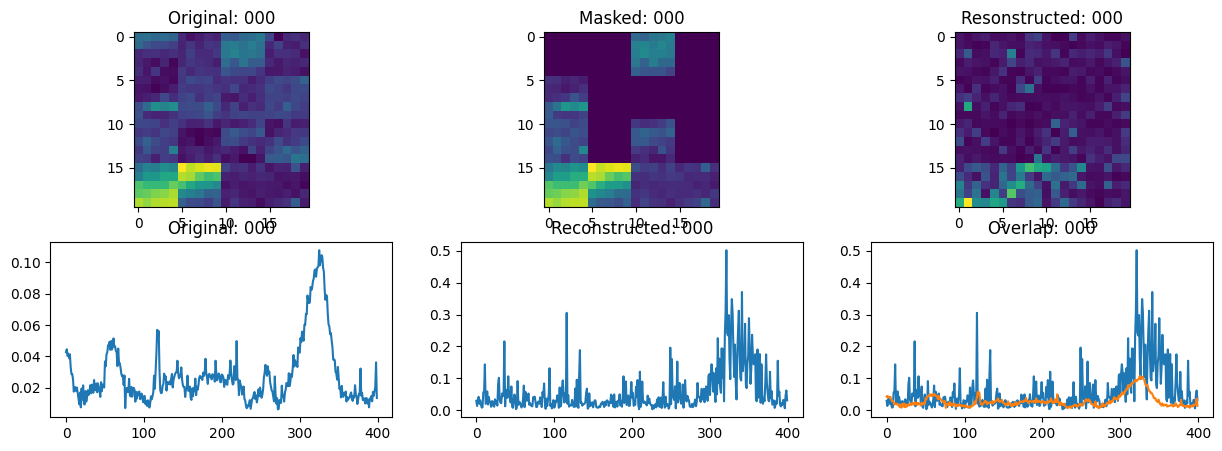

13/13 ━━━━━━━━━━━━━━━━━━━━ 46s 1s/step - loss: 0.1379 - val_loss: 0.0671
Epoch 2/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0671
Idx chosen: 149


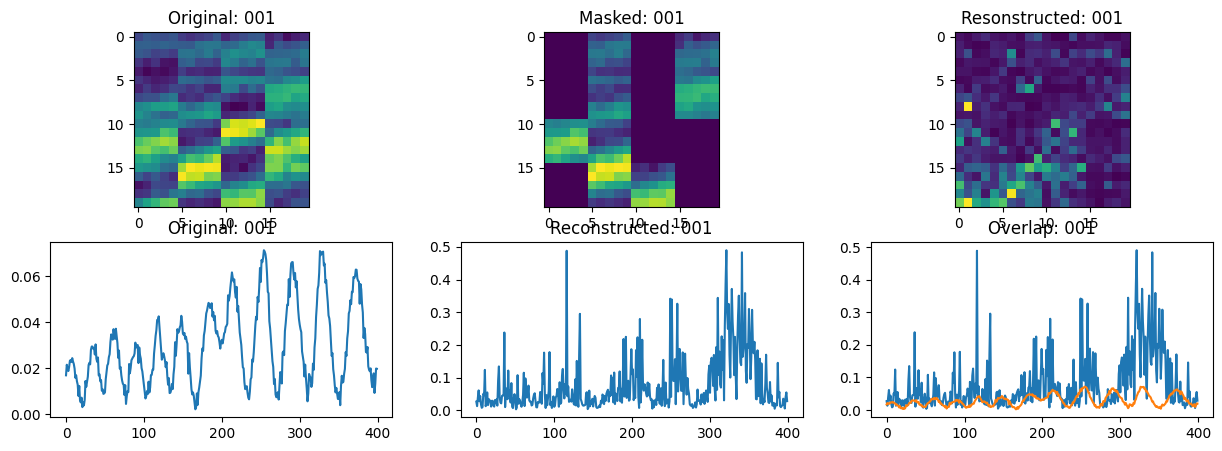

13/13 ━━━━━━━━━━━━━━━━━━━━ 16s 291ms/step - loss: 0.0671 - val_loss: 0.0674
Epoch 3/40
10/13 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0669
Idx chosen: 156


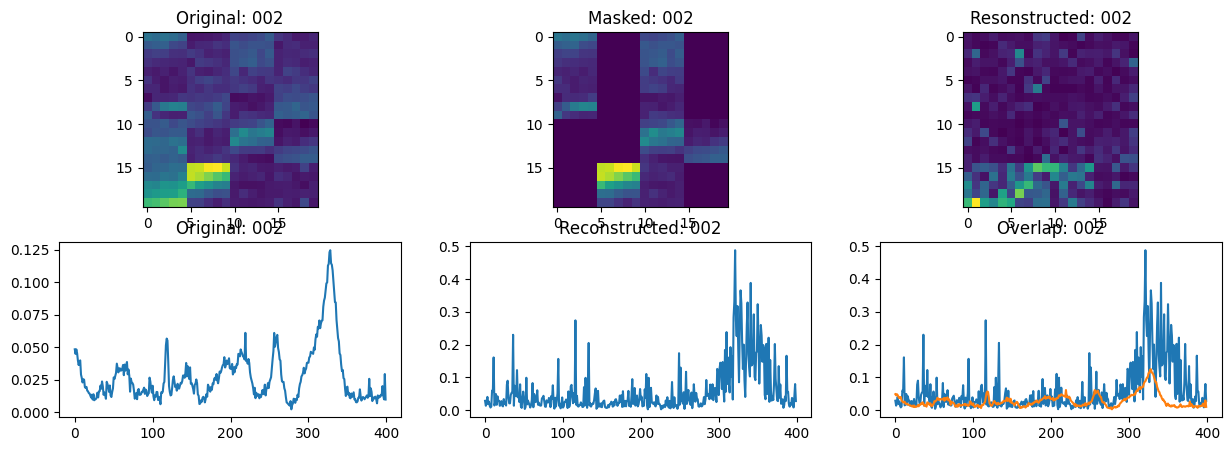

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 173ms/step - loss: 0.0670 - val_loss: 0.0671
Epoch 4/40
10/13 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0675
Idx chosen: 62


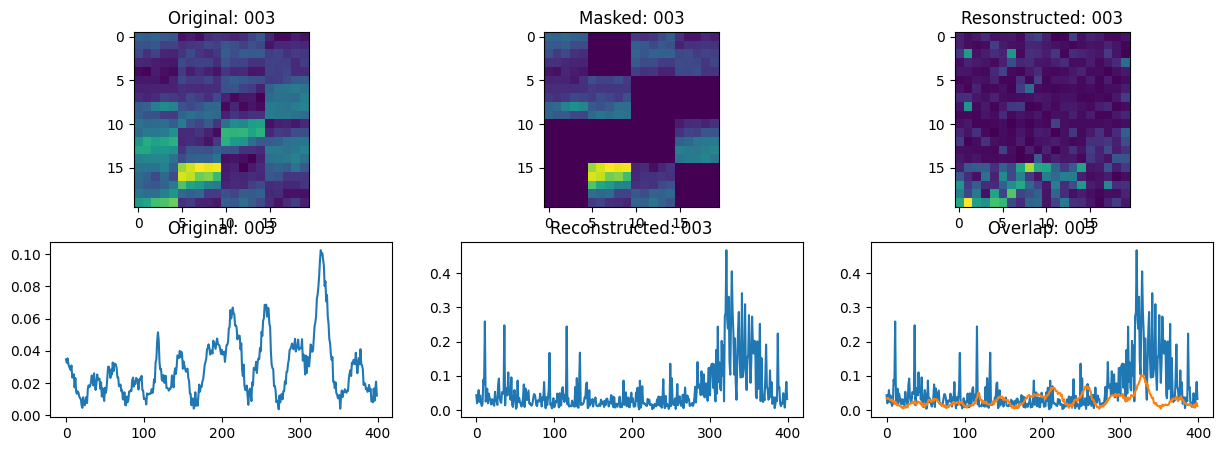

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 124ms/step - loss: 0.0676 - val_loss: 0.0672
Epoch 5/40
11/13 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0665
Idx chosen: 72


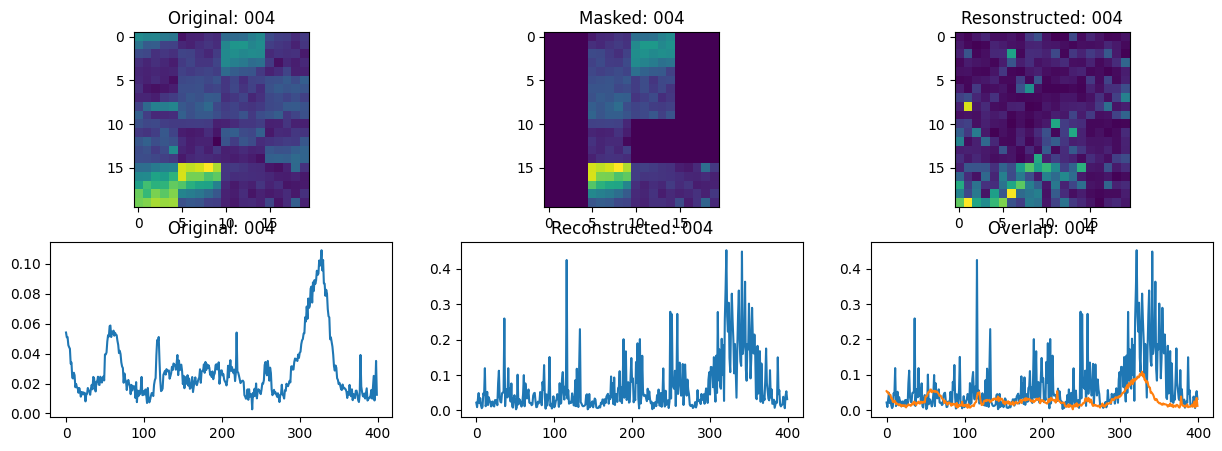

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 172ms/step - loss: 0.0666 - val_loss: 0.0671
Epoch 6/40
10/13 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0672
Idx chosen: 60


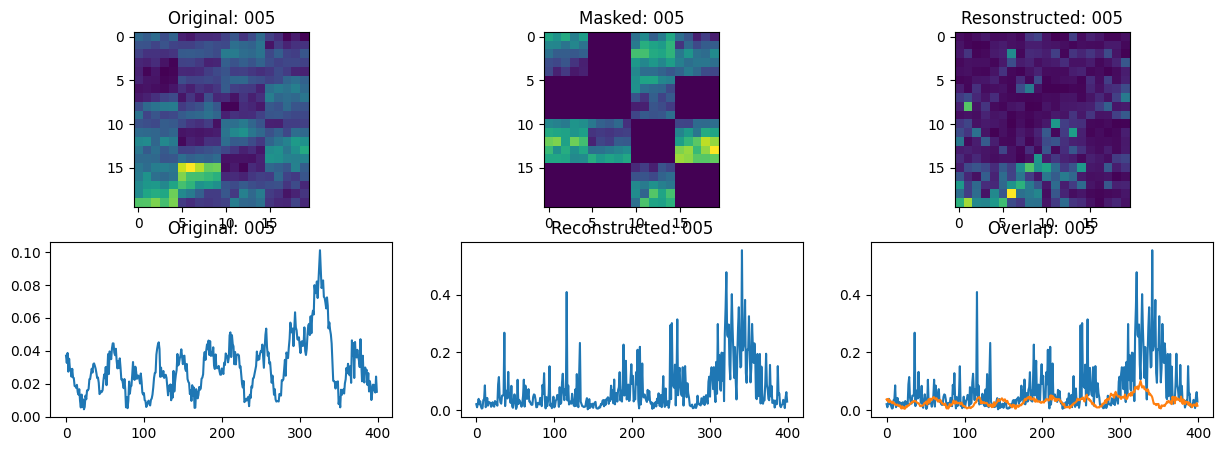

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 149ms/step - loss: 0.0672 - val_loss: 0.0673
Epoch 7/40
10/13 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0671
Idx chosen: 63


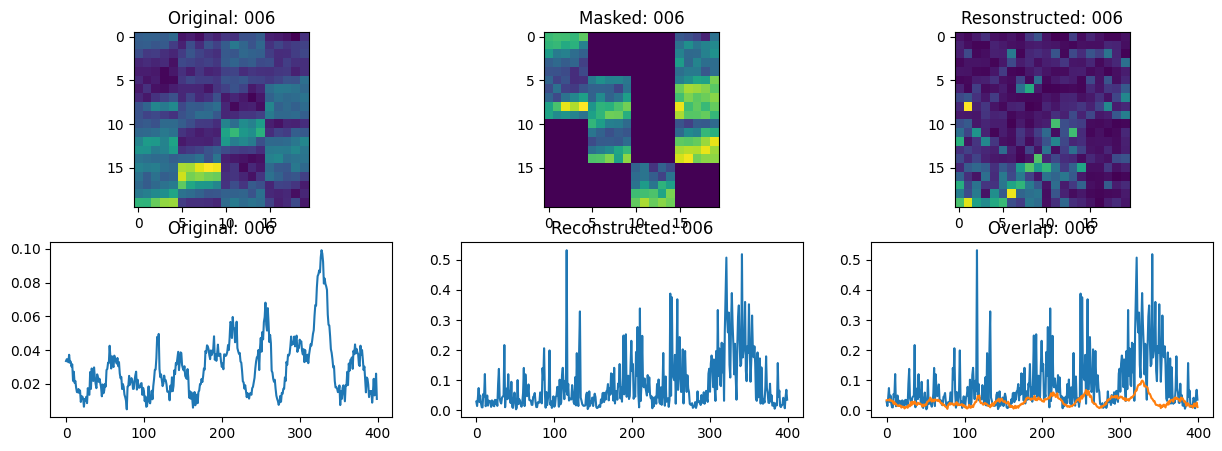

13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 307ms/step - loss: 0.0672 - val_loss: 0.0672
Epoch 8/40
11/13 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0667
Idx chosen: 68


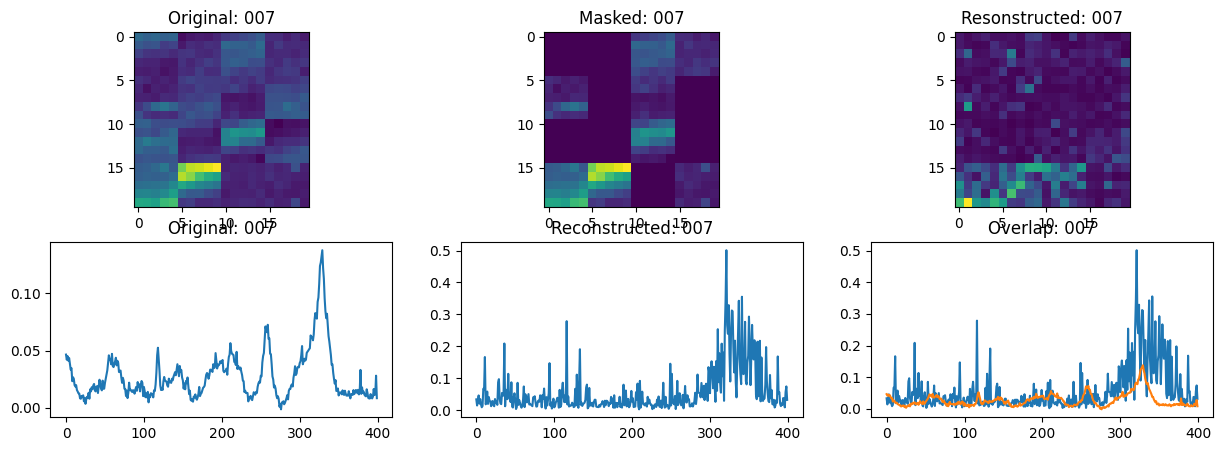

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 155ms/step - loss: 0.0668 - val_loss: 0.0672
Epoch 9/40
11/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0676
Idx chosen: 167


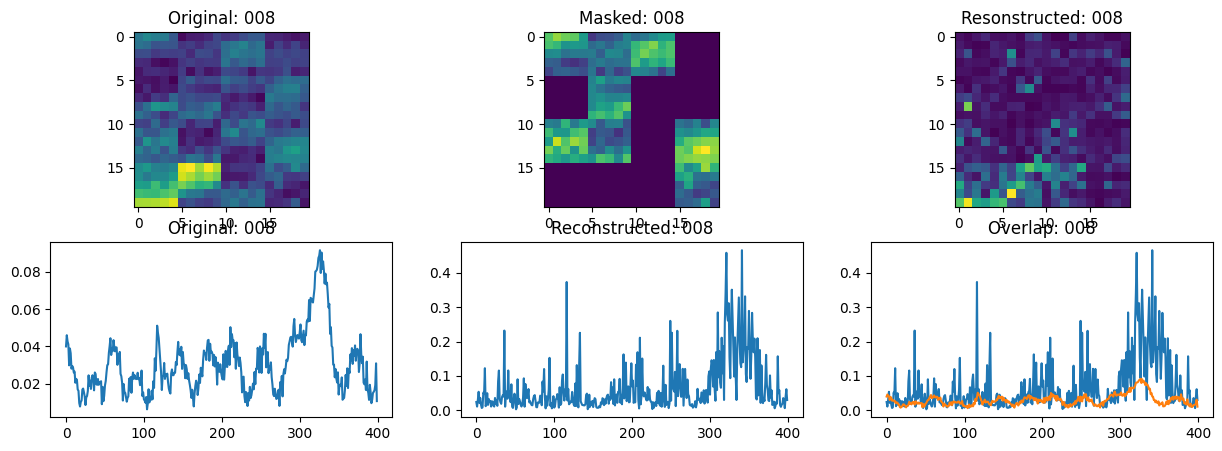

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 171ms/step - loss: 0.0675 - val_loss: 0.0673
Epoch 10/40
10/13 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0671
Idx chosen: 202


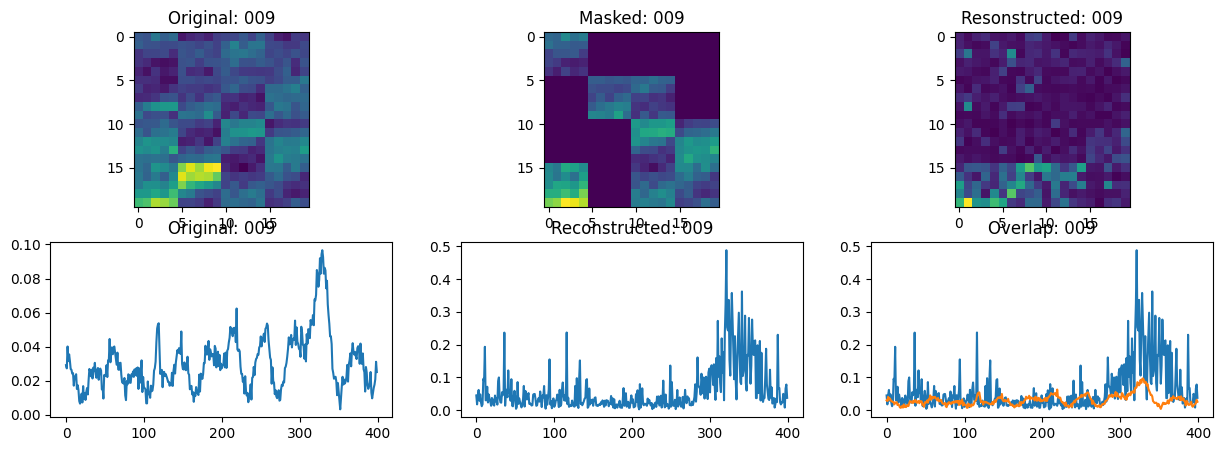

13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 175ms/step - loss: 0.0671 - val_loss: 0.0673
Epoch 11/40
11/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0669
Idx chosen: 128


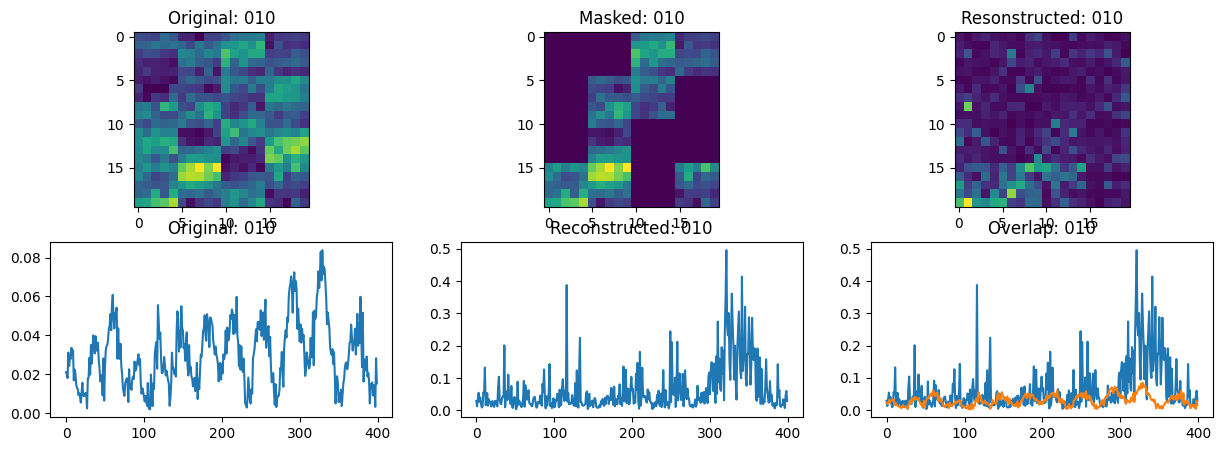

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 136ms/step - loss: 0.0670 - val_loss: 0.0671
Epoch 12/40
12/13 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0669
Idx chosen: 244


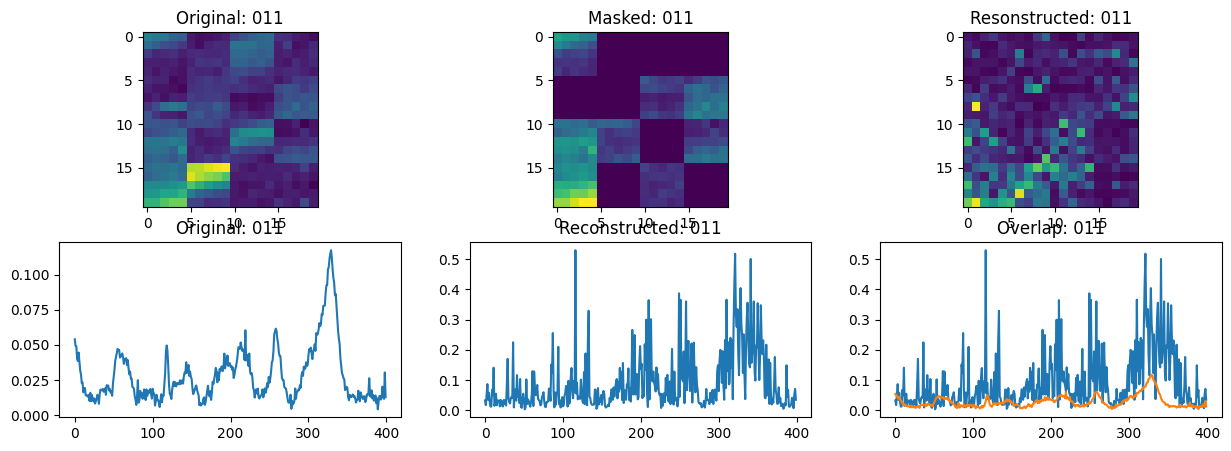

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 178ms/step - loss: 0.0669 - val_loss: 0.0670
Epoch 13/40
10/13 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0672
Idx chosen: 105


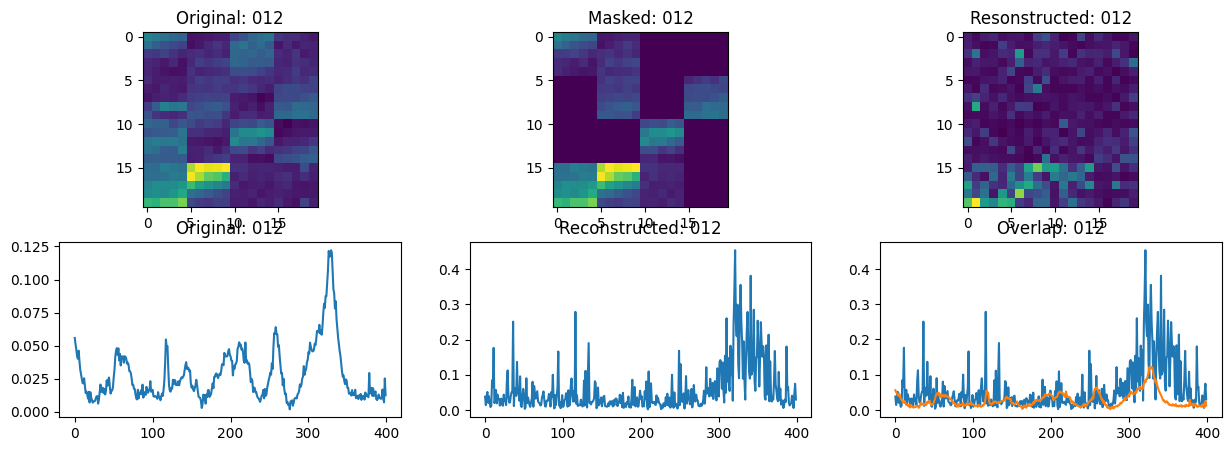

13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 204ms/step - loss: 0.0671 - val_loss: 0.0673
Epoch 14/40
12/13 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0673
Idx chosen: 64


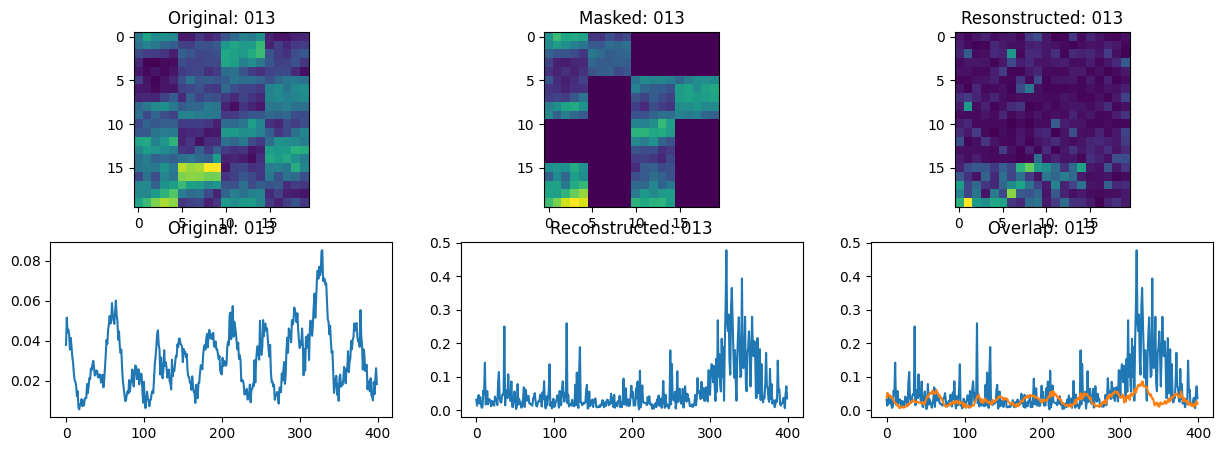

13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 196ms/step - loss: 0.0673 - val_loss: 0.0671
Epoch 15/40
11/13 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0665
Idx chosen: 121


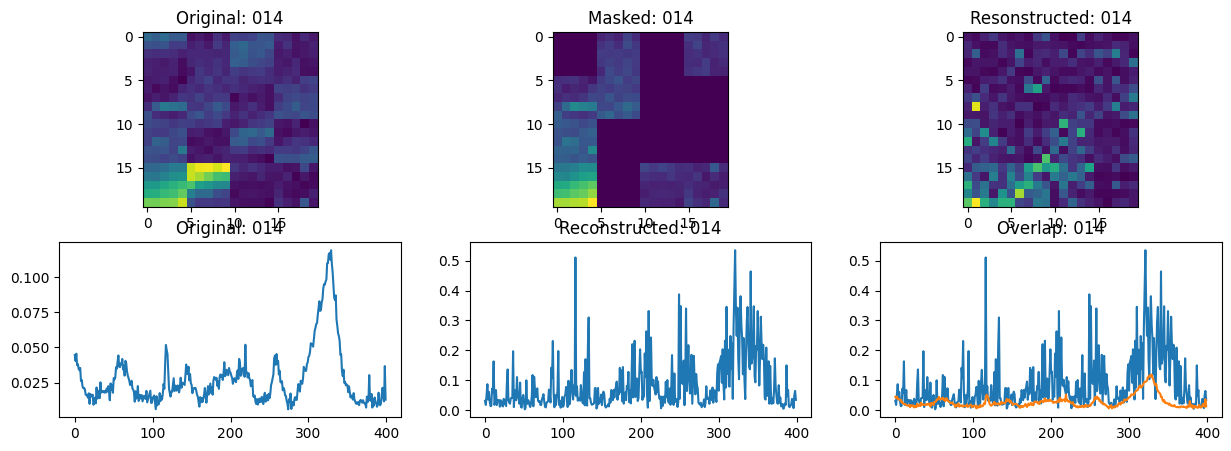

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 139ms/step - loss: 0.0666 - val_loss: 0.0671
Epoch 16/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0673
Idx chosen: 61


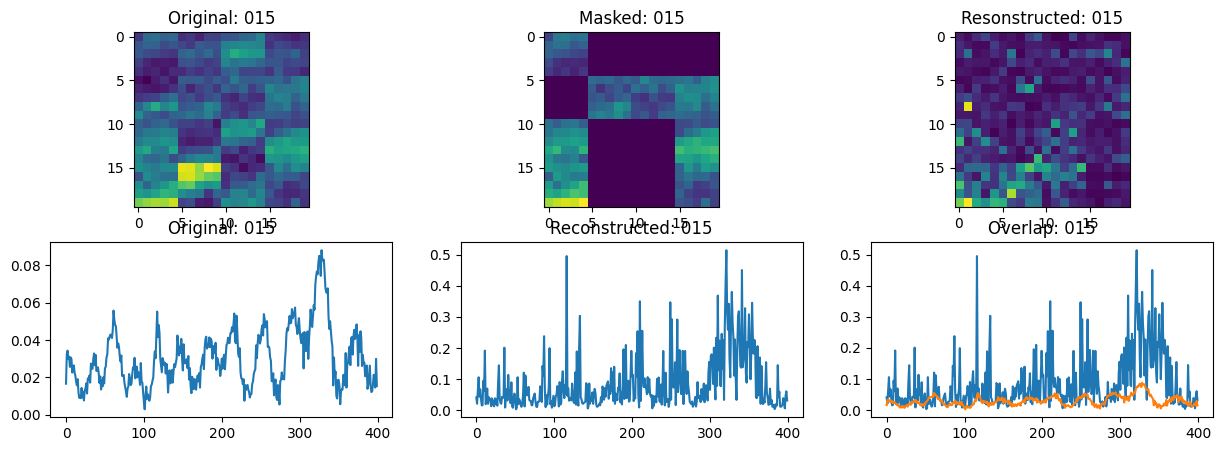

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 133ms/step - loss: 0.0673 - val_loss: 0.0671
Epoch 17/40
11/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0666
Idx chosen: 181


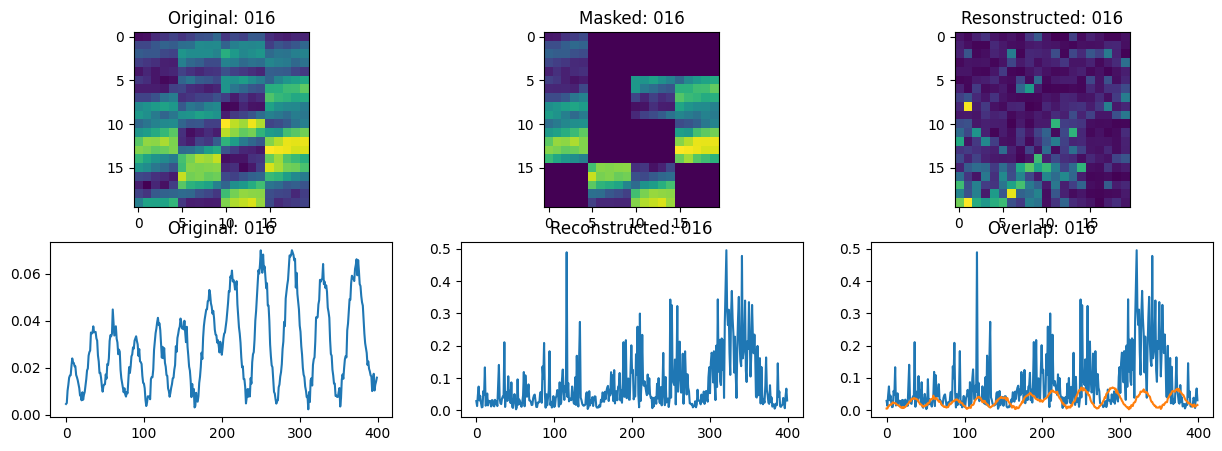

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 128ms/step - loss: 0.0666 - val_loss: 0.0673
Epoch 18/40
10/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0675
Idx chosen: 102


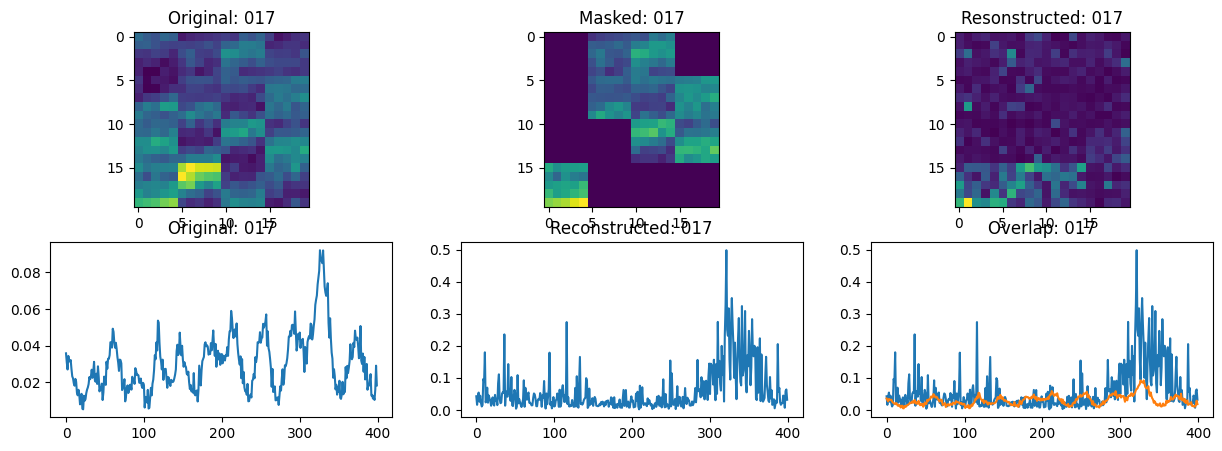

13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 210ms/step - loss: 0.0674 - val_loss: 0.0673
Epoch 19/40
12/13 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0674
Idx chosen: 59


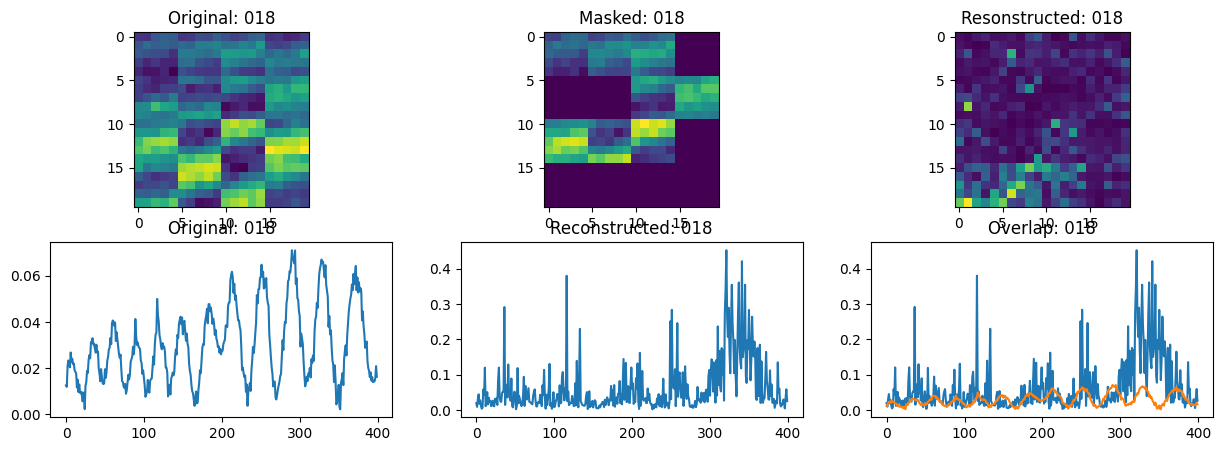

13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 304ms/step - loss: 0.0674 - val_loss: 0.0670
Epoch 20/40
12/13 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0662
Idx chosen: 45


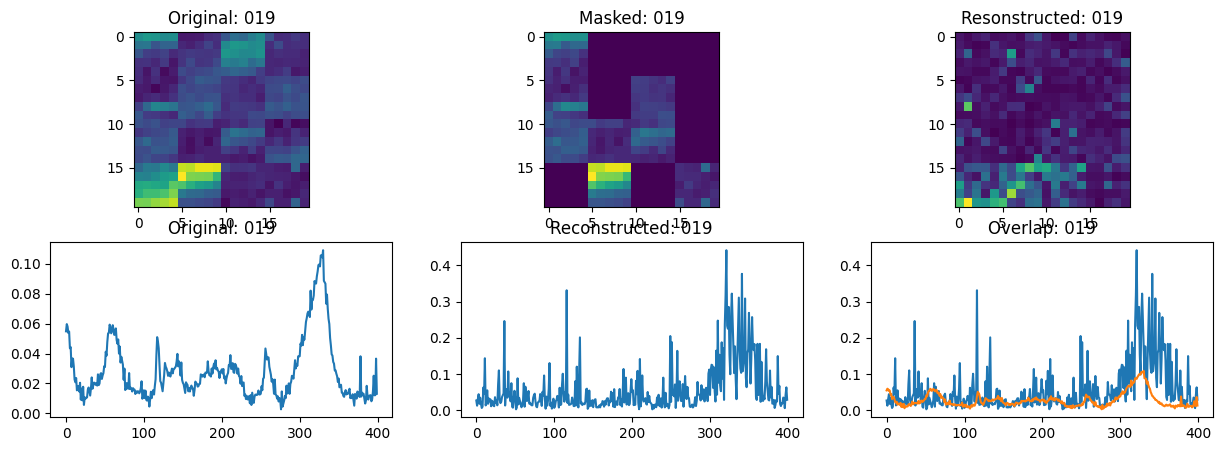

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 131ms/step - loss: 0.0663 - val_loss: 0.0671
Epoch 21/40
10/13 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0672
Idx chosen: 4


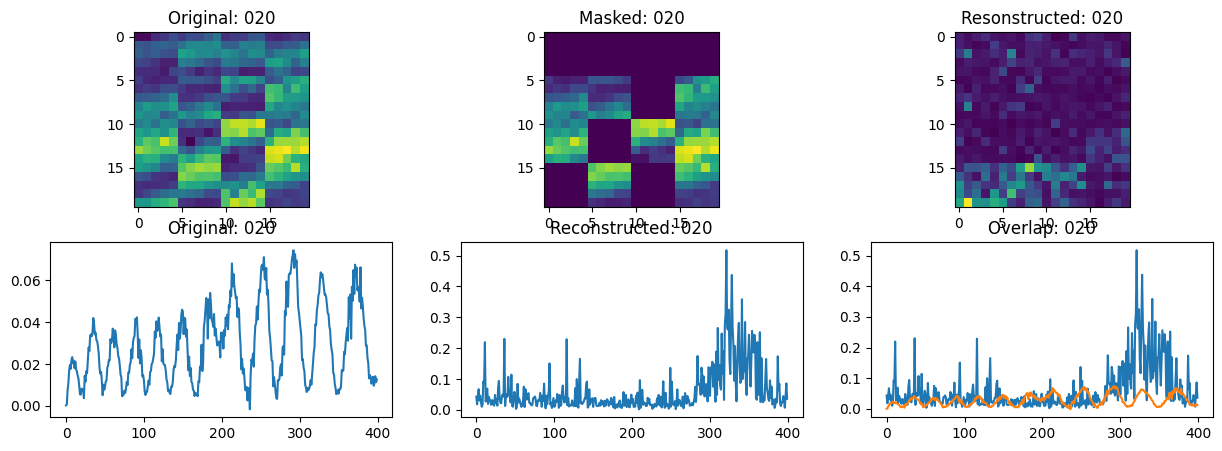

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 129ms/step - loss: 0.0673 - val_loss: 0.0671
Epoch 22/40
 9/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0676
Idx chosen: 112


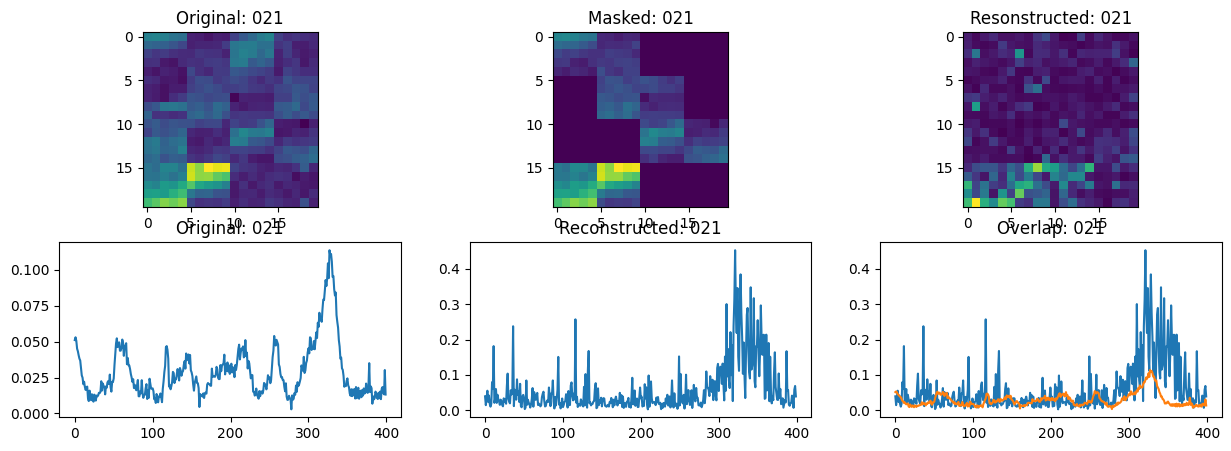

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 175ms/step - loss: 0.0675 - val_loss: 0.0673
Epoch 23/40
11/13 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0678
Idx chosen: 149


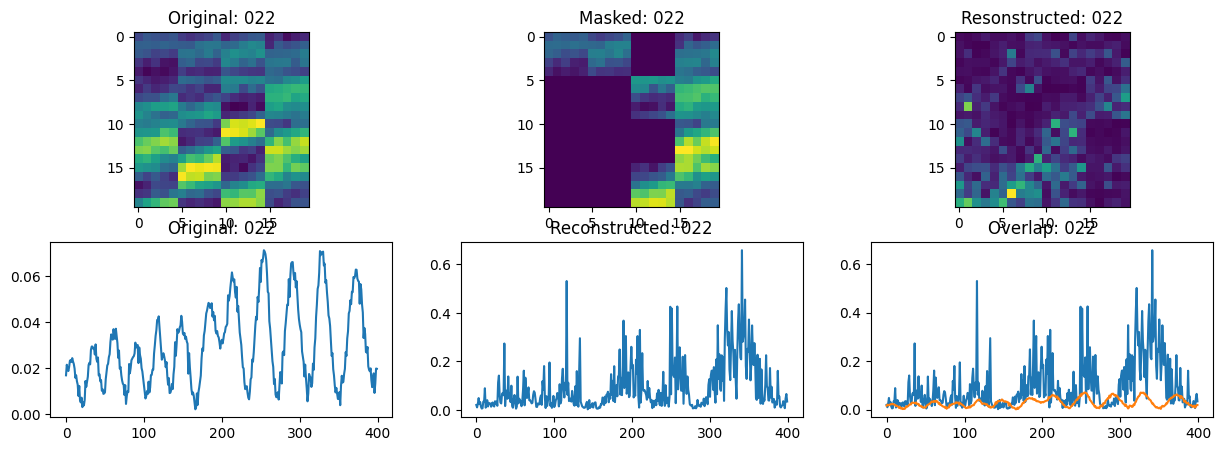

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 178ms/step - loss: 0.0677 - val_loss: 0.0673
Epoch 24/40
12/13 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0680
Idx chosen: 217


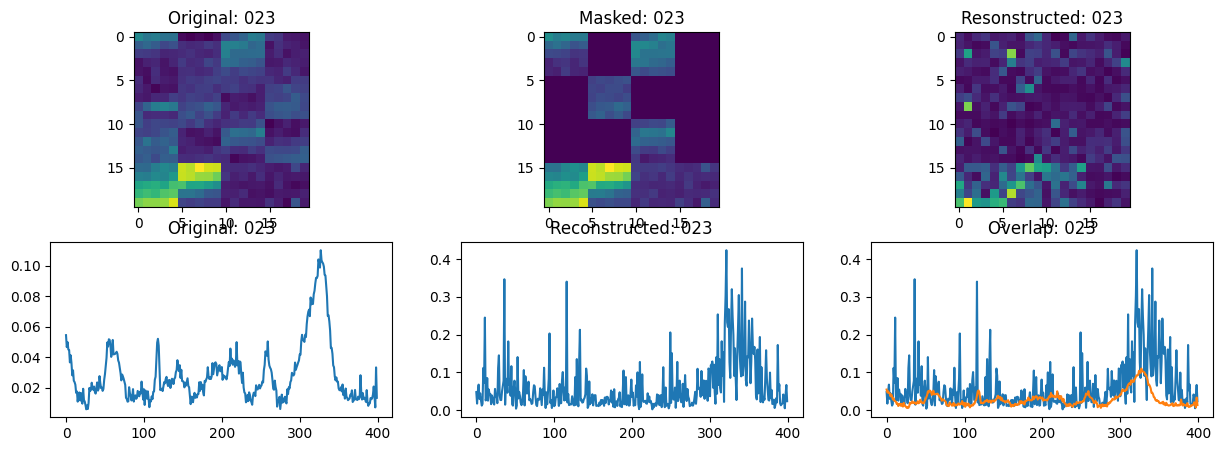

13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 206ms/step - loss: 0.0679 - val_loss: 0.0673
Epoch 25/40
12/13 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0674
Idx chosen: 180


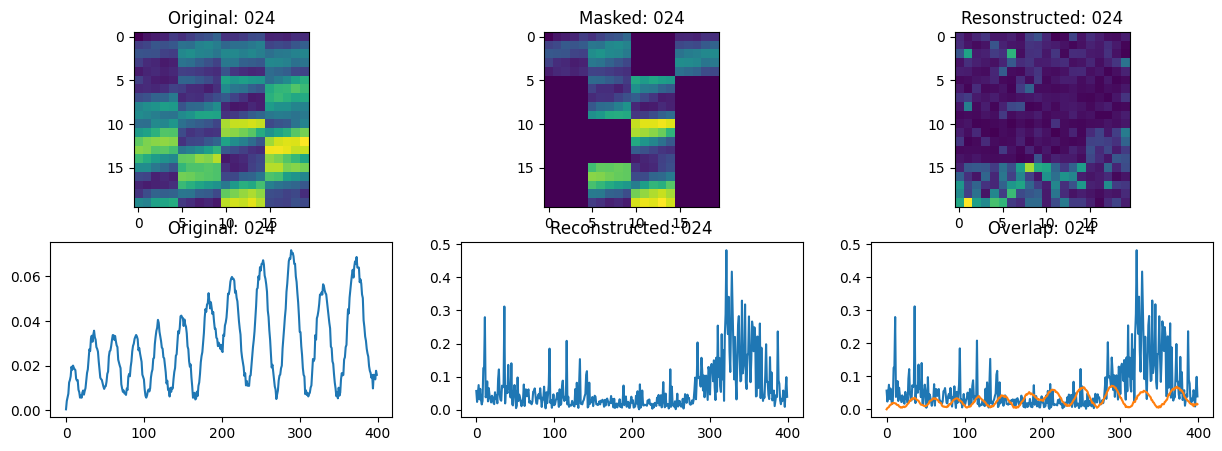

13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 178ms/step - loss: 0.0673 - val_loss: 0.0671
Epoch 26/40
12/13 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0667
Idx chosen: 69


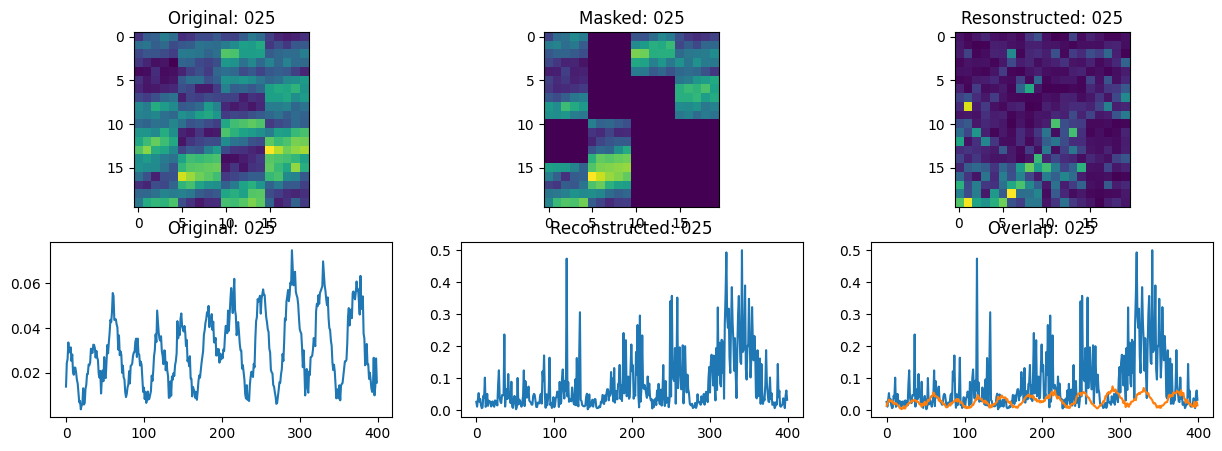

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 131ms/step - loss: 0.0668 - val_loss: 0.0672
Epoch 27/40
12/13 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0669
Idx chosen: 159


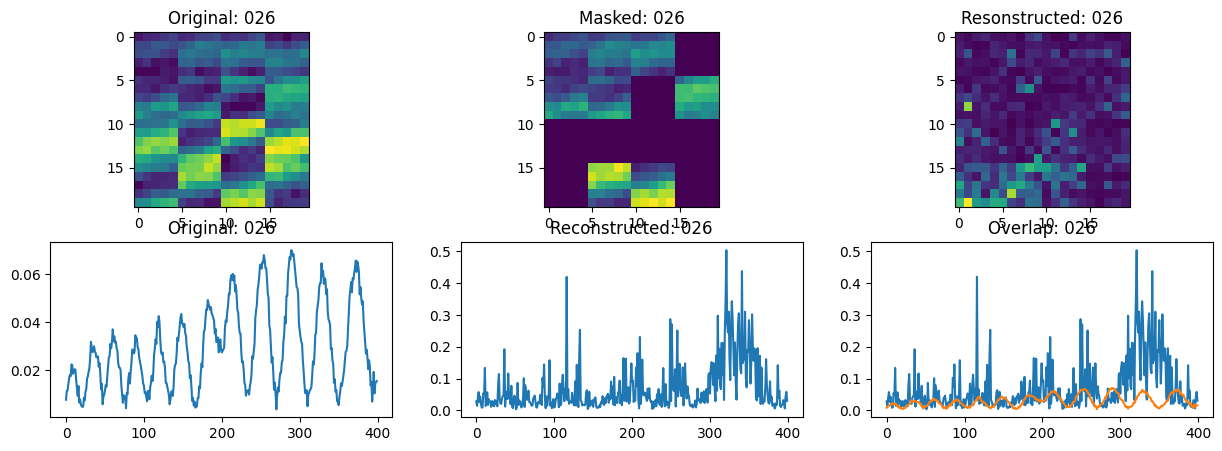

13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 184ms/step - loss: 0.0669 - val_loss: 0.0671
Epoch 28/40
12/13 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0676
Idx chosen: 239


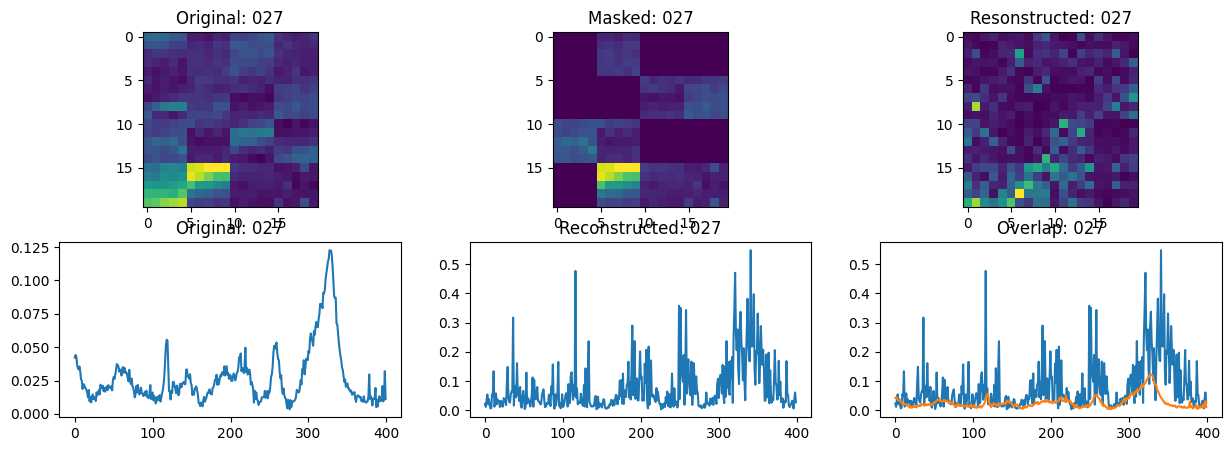

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 140ms/step - loss: 0.0676 - val_loss: 0.0668
Epoch 29/40
12/13 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0673
Idx chosen: 10


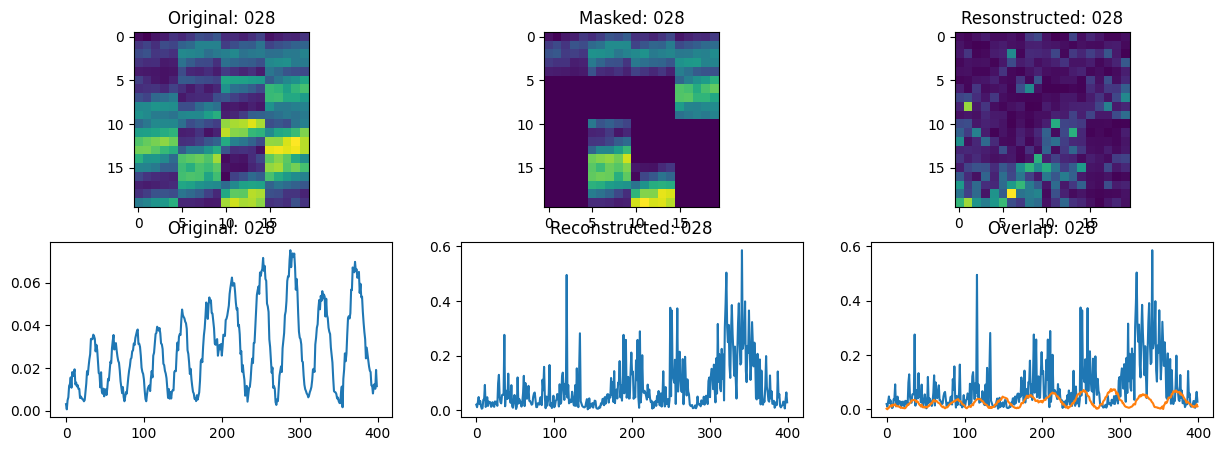

13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 274ms/step - loss: 0.0673 - val_loss: 0.0668
Epoch 30/40
12/13 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0672
Idx chosen: 137


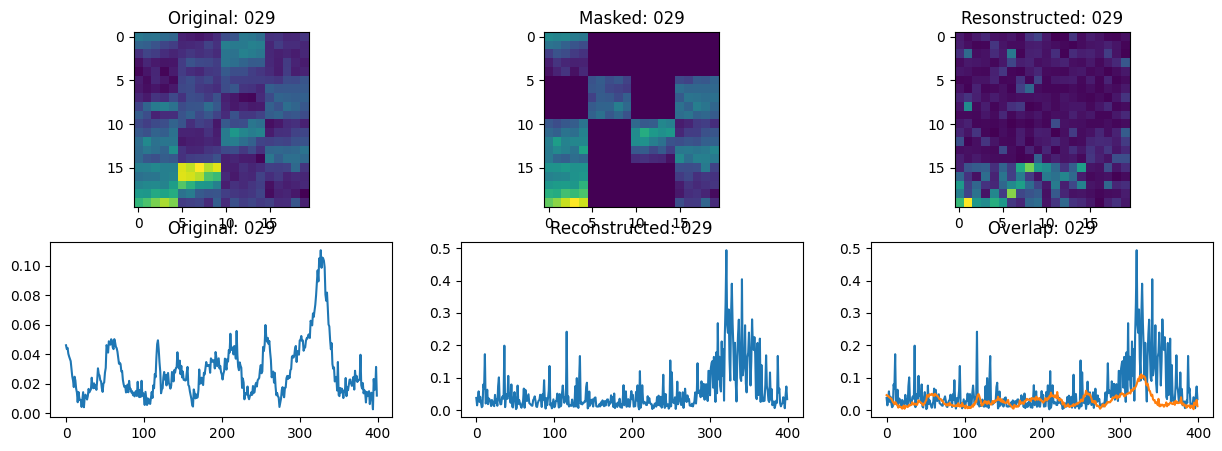

13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 236ms/step - loss: 0.0672 - val_loss: 0.0671
Epoch 31/40
12/13 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0673
Idx chosen: 238


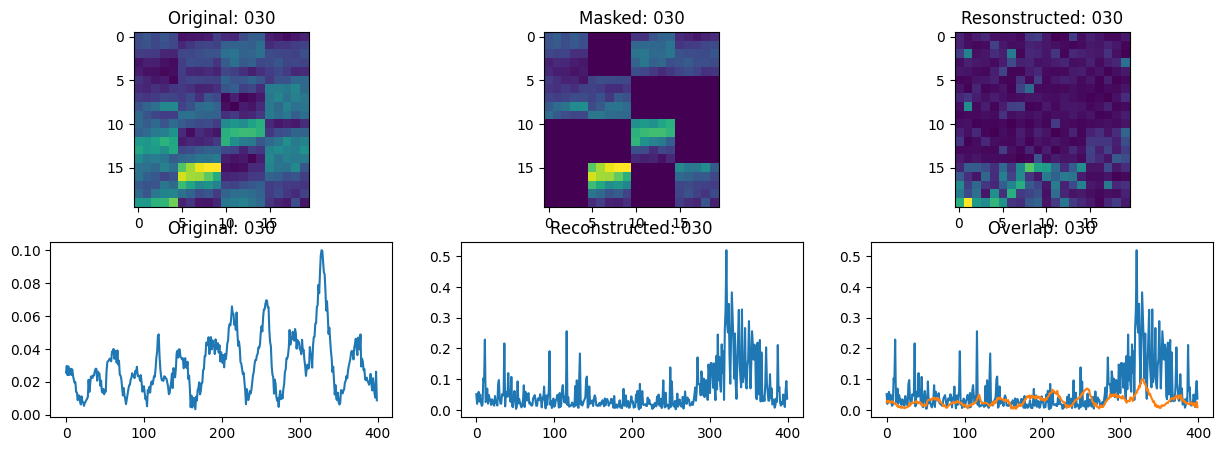

13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 185ms/step - loss: 0.0673 - val_loss: 0.0671
Epoch 32/40
12/13 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0678
Idx chosen: 166


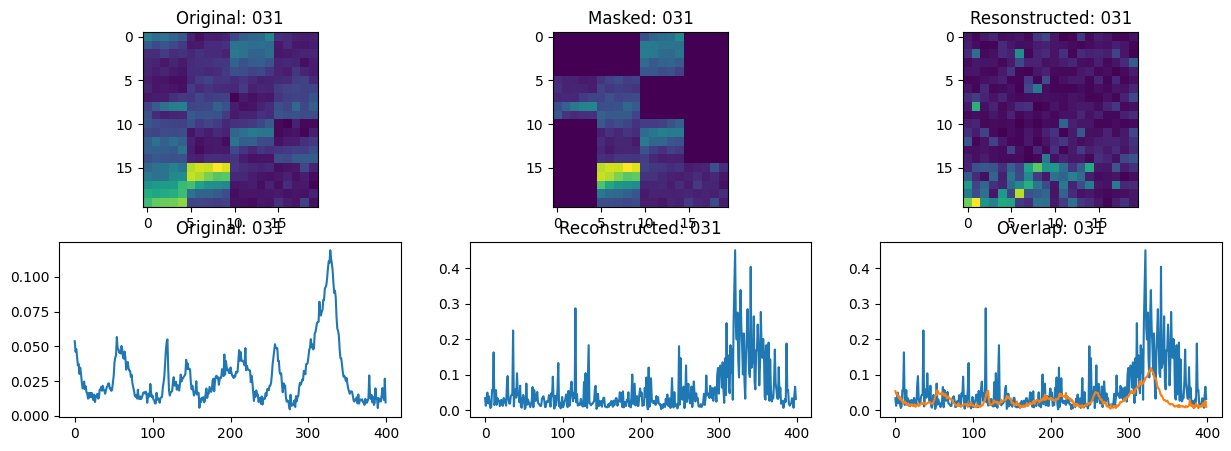

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 136ms/step - loss: 0.0678 - val_loss: 0.0672
Epoch 33/40
10/13 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0669
Idx chosen: 246


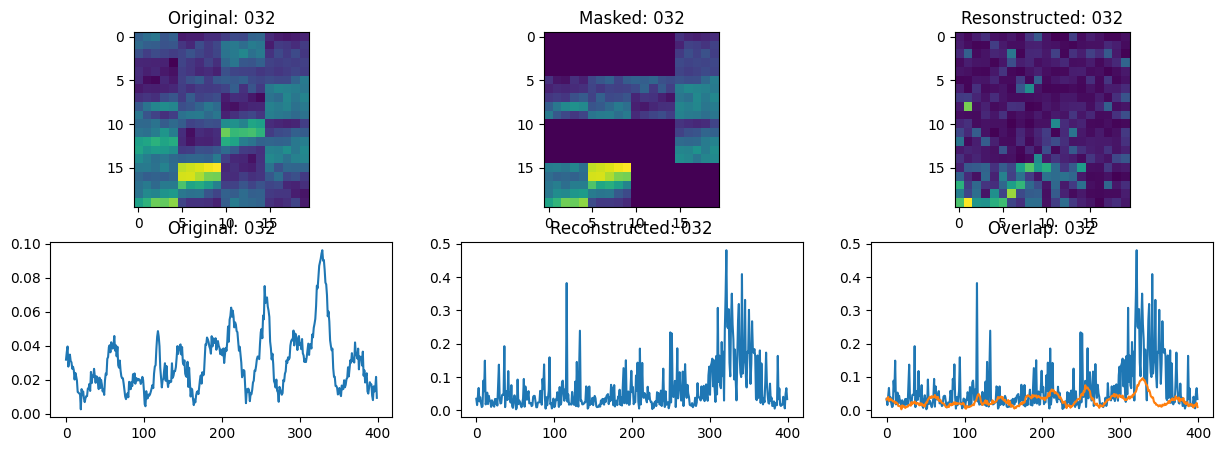

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 179ms/step - loss: 0.0669 - val_loss: 0.0673
Epoch 34/40
12/13 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0673
Idx chosen: 97


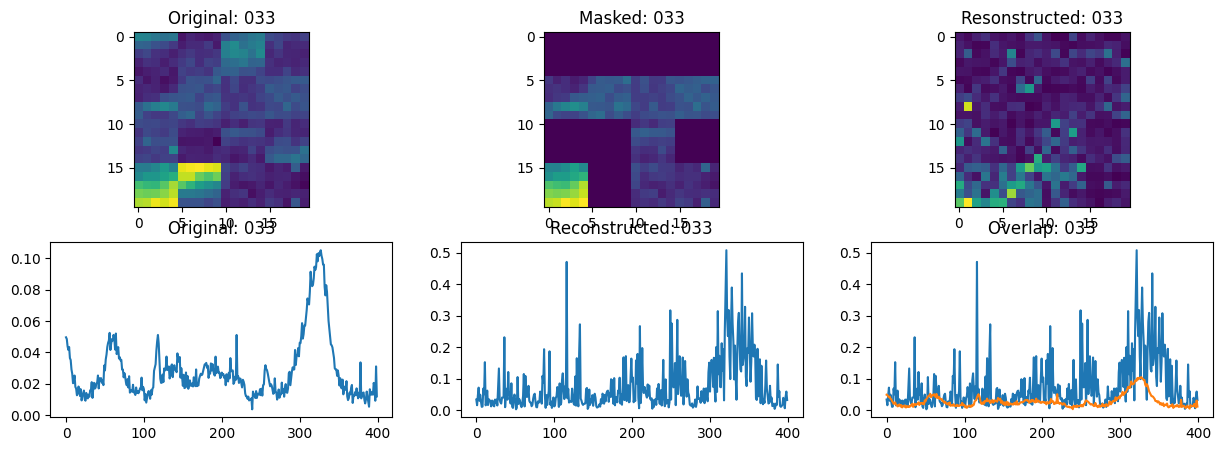

13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 307ms/step - loss: 0.0672 - val_loss: 0.0672
Epoch 35/40
10/13 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0668
Idx chosen: 30


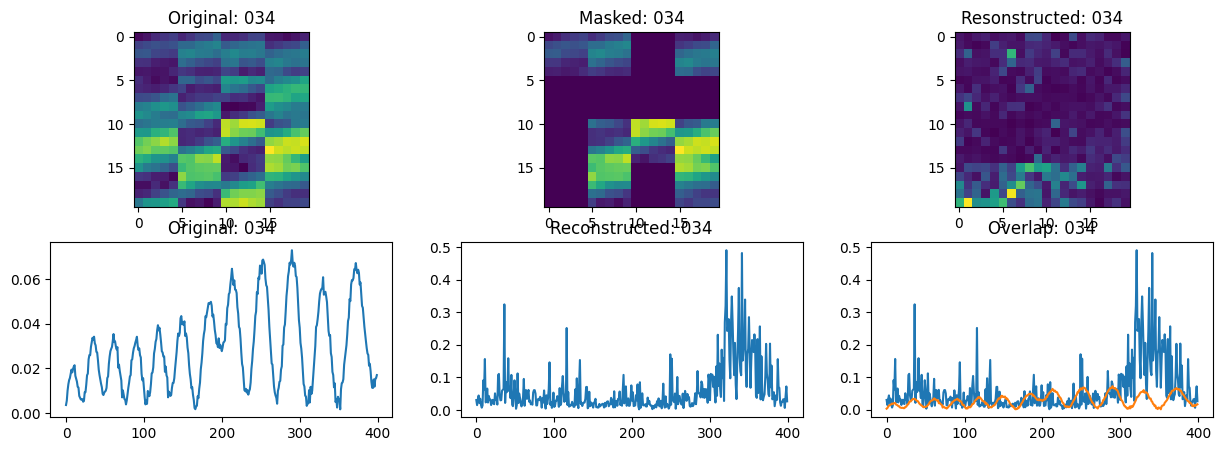

13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 182ms/step - loss: 0.0668 - val_loss: 0.0672
Epoch 36/40
10/13 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0676
Idx chosen: 11


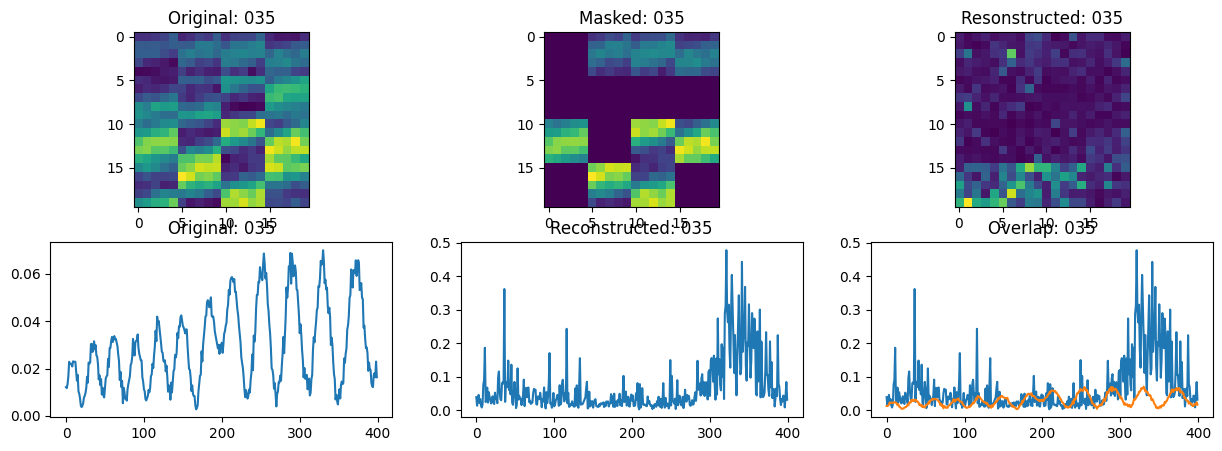

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 131ms/step - loss: 0.0674 - val_loss: 0.0670
Epoch 37/40
10/13 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0667
Idx chosen: 242


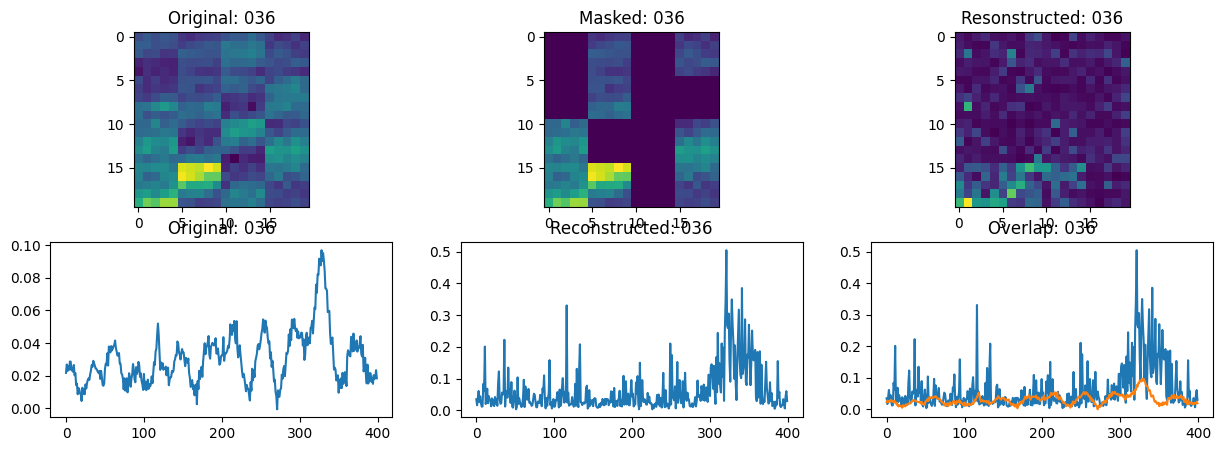

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 182ms/step - loss: 0.0668 - val_loss: 0.0672
Epoch 38/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0666
Idx chosen: 107


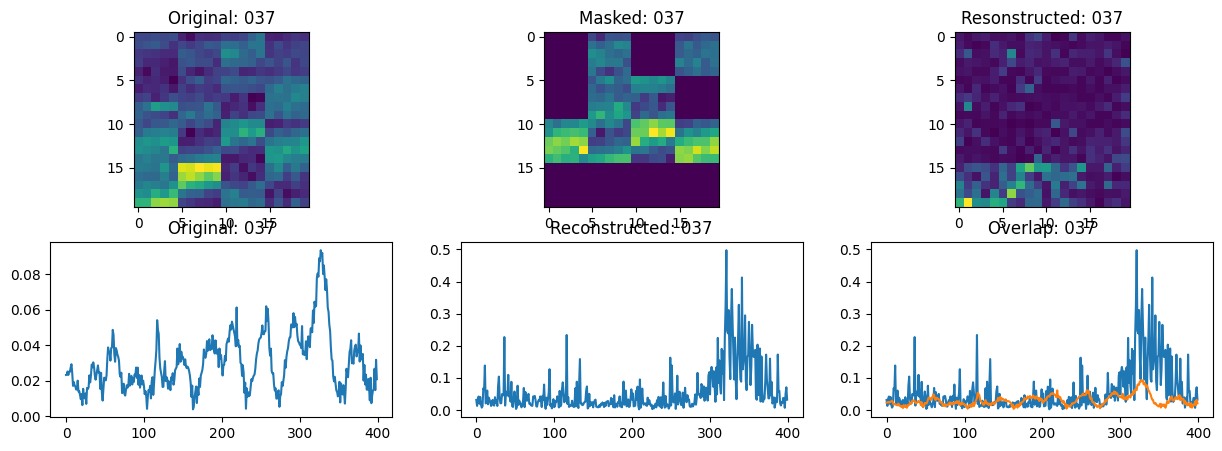

13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 205ms/step - loss: 0.0666 - val_loss: 0.0672
Epoch 39/40
10/13 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0672
Idx chosen: 79


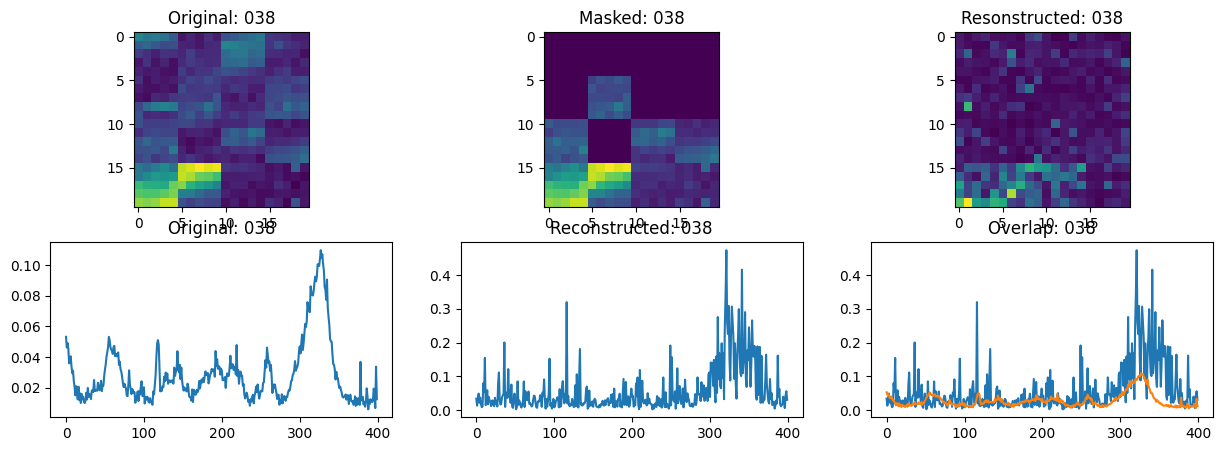

13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 181ms/step - loss: 0.0671 - val_loss: 0.0673
Epoch 40/40
10/13 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0674
Idx chosen: 165


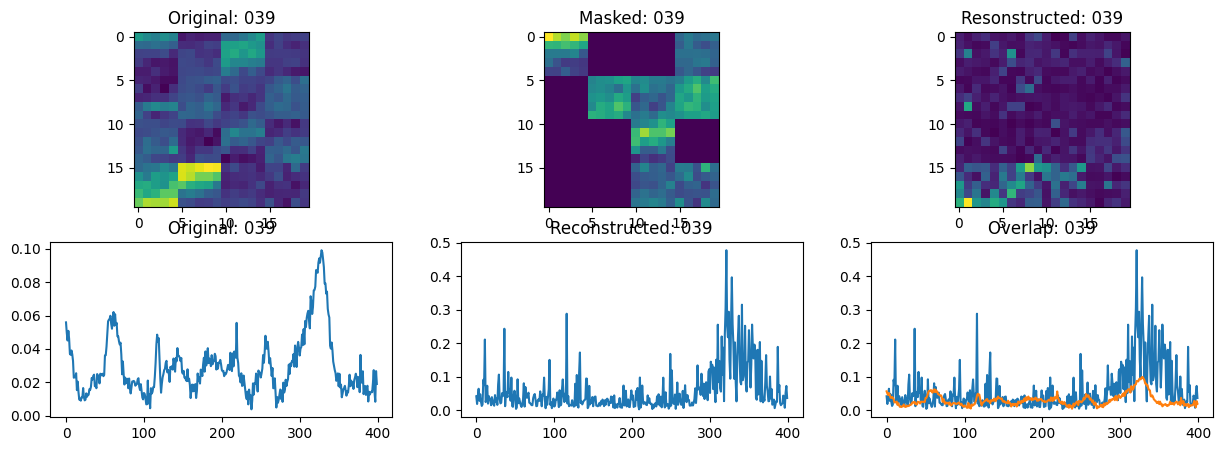

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 180ms/step - loss: 0.0673 - val_loss: 0.0672


In [ ]:
history = mae_model.fit(
    train_all_ds, epochs=40, validation_data=val_all_ds, callbacks=train_callbacks,
)

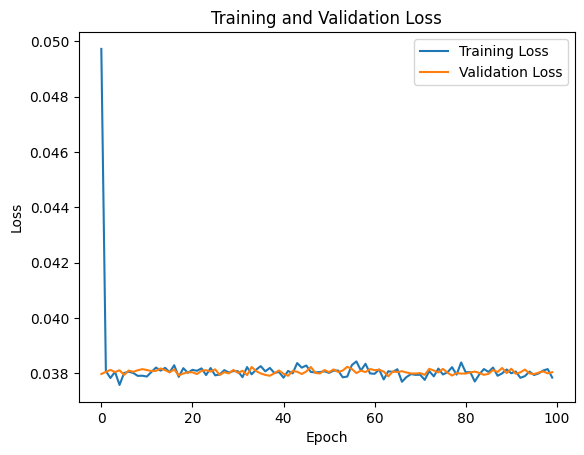

In [ ]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
# save the model

# Save the model architecture as JSON
model_json = mae_model.to_json()
with open('drive/MyDrive/Raman_ViT_data/Models/mae_model_architecture_P231CTCLM'+datetime.today().strftime('%m_%d')+'.json', 'w') as json_file:
    json_file.write(model_json)

# Save the model weights
mae_model.save_weights('drive/MyDrive/Raman_ViT_data/Models/mae_model_weights_P231CTCLM'+datetime.today().strftime('%m_%d')+'.weights.h5')

In [ ]:
nan_indices = np.where(np.isnan(All_spectra_red))
nan_indices[0]

array([8675, 8675, 8675, ..., 8679, 8679, 8679])

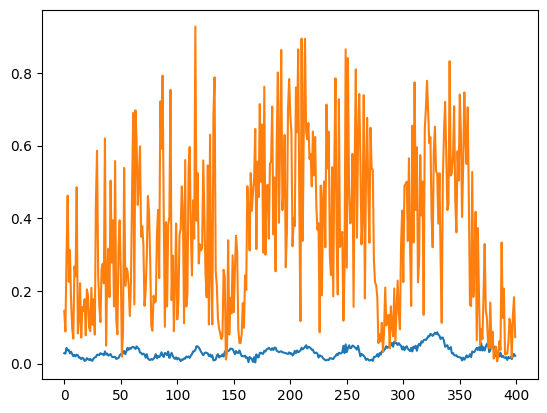

In [ ]:
# Predict from loaded model and see performance on a random sample

# pred_ds, test_im = mae_model.predict(train_all_ds)
# patch_layer = Patches()

idx = 700
pred_test = patch_layer.reconstruct_spectrum_from_image(tf.expand_dims(pred_ds[idx], axis = 0 ))
recon_test = patch_layer.reconstruct_spectrum_from_image(tf.expand_dims(test_im[idx], axis = 0 ))
plt.plot(range(len(recon_test[0])), np.transpose(recon_test))
plt.plot(range(len(pred_test[0])), np.transpose(pred_test))

In [ ]:
All_spec_filt_ds

<_PrefetchDataset element_spec=TensorSpec(shape=(None, 400), dtype=tf.float64, name=None)>